# Run Analysis (PC_1 vs PC_2, kept separate)

This notebook performs run analysis using only the two configured run IDs, with strict separation between machines:
- PC_1 (ThinkPad): `C1E07136E7B7E585`
- PC_2 (Dell): `60ABBEC6F81F86D7`

What it does:
1. Loads `query_timing` (RAPL) and `sigless` (external power) logs. External power = CH1 + CH2 (CH2 holds overflow readings logged in parallel).
2. Chunks sigless traces using `start/end` MESSAGE markers for each run.
3. Computes per-run metrics for external and RAPL data.
4. Performs A/B comparisons by query family for each PC separately.
5. Produces A/B plots for Average Power, Total Energy, and Runtime.
6. Runs per-family A/B hypothesis tests and reports which test was used.
7. Runs a cross-PC rank test to check whether family rankings agree between PCs.
8. Plots percent energy change per guideline as a forest plot (significance markers, runtime as second marker).


In [1]:
import csv
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, ttest_ind, mannwhitneyu, spearmanr

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

In [2]:
PCS = {
    "PC_1": {  # ThinkPad
        "run_id": "C1E07136E7B7E585",
        "query_timing_file": Path("../runner/logs/query_timing_thinkpad.csv"),
        "sigless_file": Path("../runner/logs/sigless.thinkpad.CH1-0.csv"),
        "overflow_file": Path("../runner/logs/sigless.thinkpad.CH2-0.csv"),  # CH2 = overflow power, added to CH1
    },
    "PC_2": {  # Dell
        "run_id": "60ABBEC6F81F86D7",
        "query_timing_file": Path("../runner/logs/query_timing_dell.csv"),
        "sigless_file": Path("../runner/logs/sigless.dell.CH1-0.csv"),
        "overflow_file": Path("../runner/logs/sigless.dell.CH2-0.csv"),  # CH2 = overflow power, added to CH1
    },
}

for pc_name, cfg in PCS.items():
    print(pc_name, cfg["run_id"])
    print("  query_timing:", cfg["query_timing_file"].resolve())
    print("  sigless (CH1):", cfg["sigless_file"].resolve())
    print("  overflow (CH2):", cfg["overflow_file"].resolve())


PC_1 C1E07136E7B7E585
  query_timing: C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\query_timing_thinkpad.csv
  sigless (CH1): C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\sigless.thinkpad.CH1-0.csv
  overflow (CH2): C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\sigless.thinkpad.CH2-0.csv
PC_2 60ABBEC6F81F86D7
  query_timing: C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\query_timing_dell.csv
  sigless (CH1): C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\sigless.dell.CH1-0.csv
  overflow (CH2): C:\Users\Matthias\Desktop\ICDE\GreenSQL\runner\logs\sigless.dell.CH2-0.csv


In [3]:
import csv
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, ttest_ind, mannwhitneyu, spearmanr

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120


def parse_message_payload(payload: str) -> dict:
    payload_obj = json.loads(payload)
    message_text = payload_obj.get("message", "")

    fields = {
        "action": None,
        "channelId": payload_obj.get("channelId"),
        "message_timestamp": payload_obj.get("timestamp"),
    }

    parts = [p.strip() for p in message_text.split(",") if p.strip()]
    if parts:
        fields["action"] = parts[0].lower()

    for token in parts[1:]:
        if "=" in token:
            k, v = token.split("=", 1)
            fields[k.strip()] = v.strip()

    return fields


def parse_loop_index(loop_value):
    if loop_value is None or (isinstance(loop_value, float) and np.isnan(loop_value)):
        return np.nan
    text = str(loop_value).strip()
    if "/" in text:
        text = text.split("/", 1)[0]
    try:
        return int(text)
    except ValueError:
        return np.nan


def parse_test_name(test_name: str):
    m = re.match(r"^(?P<family>.+)-query(?P<variant>[AB])\.sql$", str(test_name))
    if not m:
        return None, None
    return m.group("family"), f"QUERY{m.group('variant').upper()}"


# CH2 carries overflow power readings that run in parallel with CH1.
# Total external power = CH1 + nearest CH2 sample (within tolerance; 0 W if no CH2 sample is close enough).
OVERFLOW_MATCH_TOLERANCE_MS = 20


def load_overflow_power(path):
    """Load CH2 POWER samples as sorted (timestamp_ms, watts) arrays, or None if unavailable."""
    if path is None or not Path(path).exists():
        return None
    raw = pd.read_csv(
        path,
        usecols=["timestamp", "action", "payload"],
        dtype={"timestamp": "int64", "action": "category"},
    )
    raw = raw[raw["action"].astype(str).str.startswith("POWER")]
    watts = pd.to_numeric(raw["payload"], errors="coerce")
    ok = watts.notna()
    ts = raw.loc[ok, "timestamp"].to_numpy(dtype="int64")
    w = watts[ok].to_numpy(dtype=float)
    order = np.argsort(ts, kind="stable")
    return ts[order], w[order]


def add_overflow_power(timestamps, power_w, overflow, tol_ms: int = OVERFLOW_MATCH_TOLERANCE_MS):
    """Return power_w + CH2 overflow matched to each timestamp (nearest within tol_ms, else 0)."""
    power_w = np.asarray(power_w, dtype=float)
    if overflow is None:
        return power_w
    ots, ow = overflow
    if len(ots) == 0:
        return power_w
    timestamps = np.asarray(timestamps, dtype="int64")
    idx = np.searchsorted(ots, timestamps)
    left = np.clip(idx - 1, 0, len(ots) - 1)
    right = np.clip(idx, 0, len(ots) - 1)
    pick = np.where(np.abs(ots[left] - timestamps) <= np.abs(ots[right] - timestamps), left, right)
    matched = np.abs(ots[pick] - timestamps) <= tol_ms
    return power_w + np.where(matched, ow[pick], 0.0)


def build_external_metrics(sigless_file: Path, run_id_filter: str, overflow=None) -> pd.DataFrame:
    records = []
    active_run = None
    active_power_rows = []

    with sigless_file.open("r", newline="", encoding="utf-8") as handle:
        reader = csv.reader(handle)
        header = next(reader, None)

        for row in reader:
            if len(row) < 4:
                continue

            ts_raw, channel, action, payload = row[0], row[1], row[2].strip(), row[3]
            try:
                timestamp = int(ts_raw)
            except ValueError:
                continue

            if action == "MESSAGE":
                msg = parse_message_payload(payload)
                msg_action = msg.get("action")

                if msg_action == "start":
                    if str(msg.get("run_id", "")) != run_id_filter:
                        continue

                    if active_run is not None:
                        active_run["status"] = "incomplete_missing_end"
                        records.append(active_run)

                    active_run = {
                        "run_id": str(msg.get("run_id")),
                        "test_name": msg.get("test"),
                        "loop_raw": msg.get("loop"),
                        "loop_index": parse_loop_index(msg.get("loop")),
                        "runs": pd.to_numeric(msg.get("runs"), errors="coerce"),
                        "start_ts": timestamp,
                        "status": "open",
                    }
                    active_power_rows = []

                elif msg_action == "end" and active_run is not None:
                    active_run["end_ts"] = timestamp
                    active_run["elapsed_sec_message"] = pd.to_numeric(msg.get("elapsed_sec"), errors="coerce")
                    active_run["failures_message"] = pd.to_numeric(msg.get("failures"), errors="coerce")

                    power_df = pd.DataFrame(active_power_rows)
                    if not power_df.empty:
                        power_df = power_df.sort_values("timestamp").reset_index(drop=True)
                        power_df["power_w"] = add_overflow_power(power_df["timestamp"].to_numpy(), power_df["power_w"].to_numpy(), overflow)
                        power_df["time_s"] = (power_df["timestamp"] - power_df["timestamp"].min()) / 1000.0
                        measured_window_sec = float(power_df["time_s"].iloc[-1]) if len(power_df) > 1 else 0.0
                        energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
                        avg_power_w = energy_j / measured_window_sec if measured_window_sec > 0 else np.nan

                        active_run["external_samples"] = int(power_df.shape[0])
                        active_run["external_window_sec"] = measured_window_sec
                        active_run["external_energy_j"] = energy_j
                        active_run["external_avg_power_w"] = avg_power_w
                        active_run["external_peak_power_w"] = float(power_df["power_w"].max())
                        active_run["external_min_power_w"] = float(power_df["power_w"].min())
                        active_run["external_std_power_w"] = float(power_df["power_w"].std(ddof=1)) if power_df.shape[0] > 1 else 0.0
                        active_run["status"] = "complete"
                    else:
                        active_run["external_samples"] = 0
                        active_run["external_window_sec"] = np.nan
                        active_run["external_energy_j"] = np.nan
                        active_run["external_avg_power_w"] = np.nan
                        active_run["external_peak_power_w"] = np.nan
                        active_run["external_min_power_w"] = np.nan
                        active_run["external_std_power_w"] = np.nan
                        active_run["status"] = "complete_no_power_rows"

                    records.append(active_run)
                    active_run = None
                    active_power_rows = []

            elif action.startswith("POWER") and active_run is not None:
                try:
                    power_val = float(payload)
                except ValueError:
                    continue

                active_power_rows.append({"timestamp": timestamp, "power_w": power_val})

    if active_run is not None:
        active_run["status"] = "incomplete_missing_end"
        active_run["external_samples"] = len(active_power_rows)
        records.append(active_run)

    ext_df = pd.DataFrame(records)
    if ext_df.empty:
        return ext_df

    ext_df["message_duration_sec"] = (ext_df.get("end_ts", np.nan) - ext_df["start_ts"]) / 1000.0
    return ext_df


def build_rapl_metrics(query_timing_file: Path, run_id_filter: str) -> pd.DataFrame:
    qdf = pd.read_csv(query_timing_file)
    qdf = qdf[qdf["run_id"].astype(str) == str(run_id_filter)].copy()

    numeric_cols = ["loop_index", "total_elapsed_sec", "rapl_package_j", "rapl_core_j", "failures", "runs_per_loop", "total_runs"]
    for col in numeric_cols:
        if col in qdf.columns:
            qdf[col] = pd.to_numeric(qdf[col], errors="coerce")

    qdf["rapl_avg_power_w"] = qdf["rapl_package_j"] / qdf["total_elapsed_sec"]
    qdf["loop_index"] = qdf["loop_index"].astype("Int64")

    keep_cols = [
        "run_id",
        "test_name",
        "loop_index",
        "total_elapsed_sec",
        "rapl_package_j",
        "rapl_core_j",
        "rapl_avg_power_w",
        "failures",
        "runs_per_loop",
        "total_runs",
    ]
    keep_cols = [c for c in keep_cols if c in qdf.columns]
    return qdf[keep_cols].copy()

In [4]:
# Override with a robust reader for malformed lines in query_timing CSVs.
def build_rapl_metrics(query_timing_file: Path, run_id_filter: str) -> pd.DataFrame:
    qdf = pd.read_csv(query_timing_file, engine="python", on_bad_lines="skip")
    qdf = qdf[qdf["run_id"].astype(str) == str(run_id_filter)].copy()

    numeric_cols = ["loop_index", "total_elapsed_sec", "rapl_package_j", "rapl_core_j", "failures", "runs_per_loop", "total_runs"]
    for col in numeric_cols:
        if col in qdf.columns:
            qdf[col] = pd.to_numeric(qdf[col], errors="coerce")

    # Remove malformed/unphysical rows before computing average power.
    qdf = qdf.dropna(subset=["test_name", "loop_index", "total_elapsed_sec", "rapl_package_j"])
    qdf = qdf[(qdf["total_elapsed_sec"] > 0) & (qdf["rapl_package_j"] > 0)]
    qdf = qdf[(qdf["total_elapsed_sec"] < 10000) & (qdf["rapl_package_j"] < 1_000_000)]

    qdf["rapl_avg_power_w"] = qdf["rapl_package_j"] / qdf["total_elapsed_sec"]
    qdf["loop_index"] = qdf["loop_index"].astype("Int64")

    keep_cols = [
        "run_id",
        "test_name",
        "loop_index",
        "total_elapsed_sec",
        "rapl_package_j",
        "rapl_core_j",
        "rapl_avg_power_w",
        "failures",
        "runs_per_loop",
        "total_runs",
    ]
    keep_cols = [c for c in keep_cols if c in qdf.columns]
    return qdf[keep_cols].copy()

In [5]:
# Allow very large MESSAGE payload fields in sigless CSV.
csv.field_size_limit(10_000_000)

131072

In [6]:
per_pc = {}
overflow_by_pc = {pc: load_overflow_power(cfg.get("overflow_file")) for pc, cfg in PCS.items()}
for pc, ov in overflow_by_pc.items():
    print(f"{pc}: CH2 overflow samples loaded = {0 if ov is None else len(ov[0]):,}")
merged_frames = []

for pc_name, cfg in PCS.items():
    ext_df = build_external_metrics(cfg["sigless_file"], cfg["run_id"], overflow=overflow_by_pc[pc_name])
    rapl_df = build_rapl_metrics(cfg["query_timing_file"], cfg["run_id"] )

    if not ext_df.empty:
        ext_df["loop_index"] = pd.to_numeric(ext_df["loop_index"], errors="coerce").astype("Int64")

    merged = rapl_df.merge(
        ext_df,
        on=["run_id", "test_name", "loop_index"],
        how="left",
        suffixes=("", "_sigless"),
    )

    parsed = merged["test_name"].astype(str).apply(parse_test_name)
    merged["query_family"] = [p[0] for p in parsed]
    merged["variant"] = [p[1] for p in parsed]
    merged["pc"] = pc_name

    per_pc[pc_name] = {
        "rapl": rapl_df,
        "external": ext_df,
        "merged": merged,
    }
    merged_frames.append(merged)

    print(f"{pc_name} | run_id={cfg['run_id']}")
    print(f"  RAPL rows: {len(rapl_df)}")
    print(f"  Sigless run records: {len(ext_df)}")
    print(f"  Merge rows: {len(merged)}")
    print(f"  Rows with external avg power: {merged['external_avg_power_w'].notna().sum() if 'external_avg_power_w' in merged.columns else 0}")

analysis_df = pd.concat(merged_frames, ignore_index=True) if merged_frames else pd.DataFrame()

if analysis_df.empty:
    raise ValueError("No data loaded for analysis.")

display(
    analysis_df[[
        "pc", "run_id", "test_name", "loop_index", "query_family", "variant",
        "total_elapsed_sec", "rapl_package_j", "rapl_avg_power_w",
        "external_energy_j", "external_avg_power_w"
    ]].head(12)
 )

PC_1: CH2 overflow samples loaded = 15,593,270
PC_2: CH2 overflow samples loaded = 14,880,394


C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

... (48 outputs left out)

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\4006886136.py:150: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  energy_j = float(np.trapz(power_df["power_w"].to_numpy(), power_df["time_s"].to_numpy())) if len(power_df) > 1 else 0.0
C:\Users\M

PC_2 | run_id=60ABBEC6F81F86D7
  RAPL rows: 767
  Sigless run records: 770
  Merge rows: 767
  Rows with external avg power: 767


,pc,run_id,test_name,loop_index,query_family,variant,total_elapsed_sec,rapl_package_j,rapl_avg_power_w,external_energy_j,external_avg_power_w
0,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,1,APX1090,QUERYA,113.302326,794.588562,7.012994,1406.0883,12.408669
1,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,2,APX1090,QUERYA,112.889018,801.726257,7.101898,1407.2368,12.465668
2,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,3,APX1090,QUERYA,112.547764,800.712646,7.114425,1405.7155,12.490031
3,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,4,APX1090,QUERYA,112.402386,801.231934,7.128247,1405.6335,12.504746
4,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,5,APX1090,QUERYA,112.346199,802.754700,7.145366,1396.4263,12.541550
5,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,7,APX1090,QUERYA,112.358249,802.809753,7.145090,1396.4513,12.570790
6,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,8,APX1090,QUERYA,112.338562,804.946899,7.165366,1410.1440,12.552131
7,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,9,APX1090,QUERYA,112.287247,804.701843,7.166458,1407.9952,12.538919
8,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,10,APX1090,QUERYA,112.369673,804.384155,7.158374,1409.3091,12.547044
9,PC_1,C1E07136E7B7E585,APX1090-queryA.sql,11,APX1090,QUERYA,112.334232,803.996887,7.157185,1405.4124,12.511015


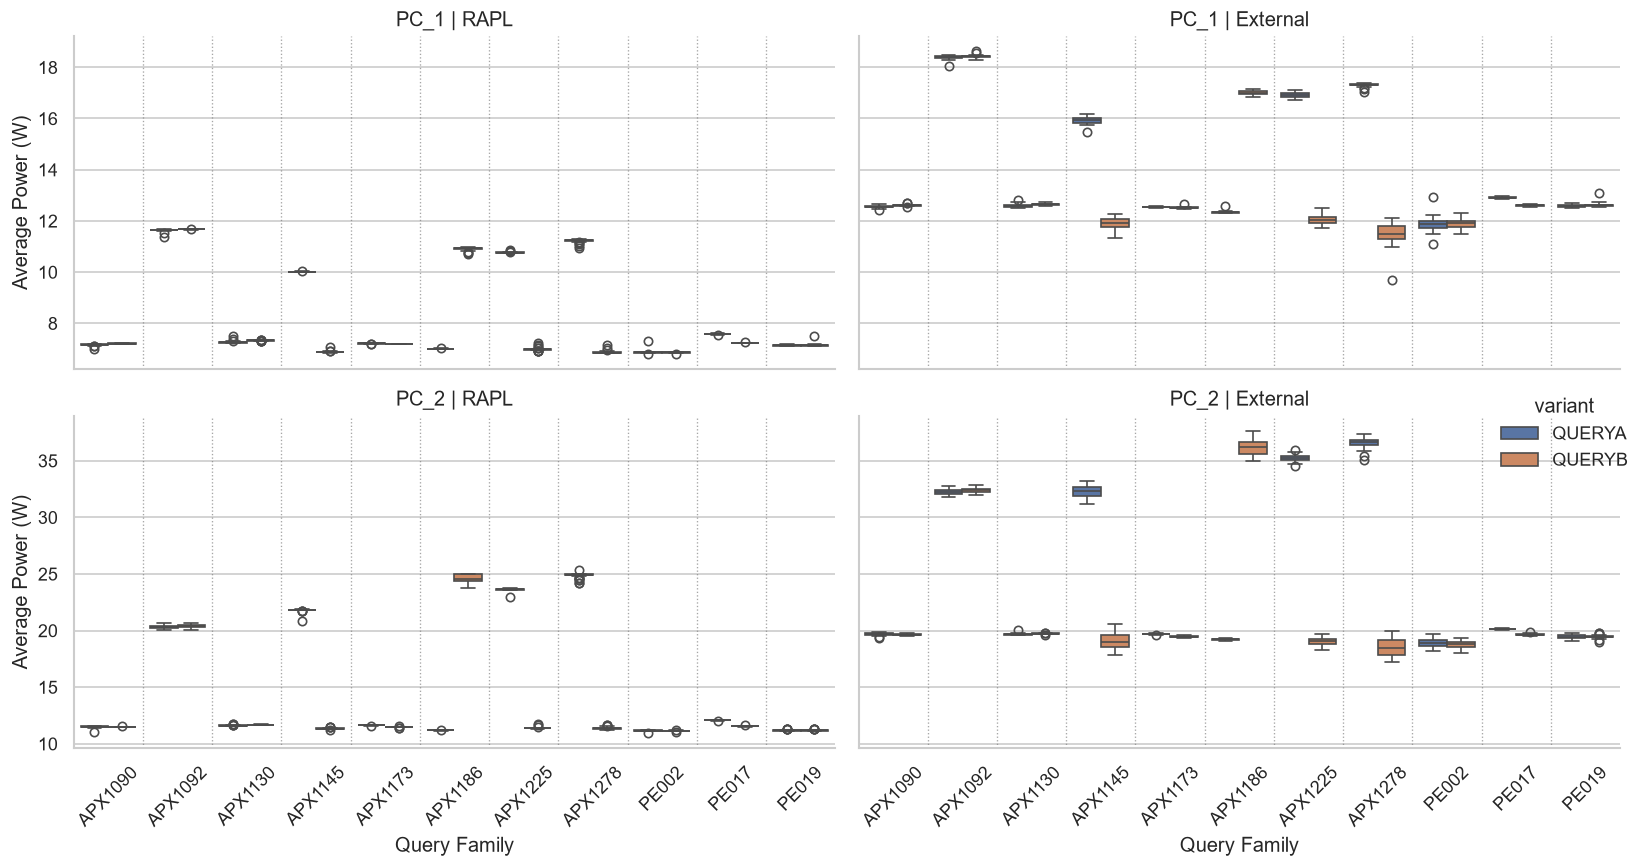

In [7]:
plot_df = analysis_df[analysis_df["variant"].isin(["QUERYA", "QUERYB"])].copy()
query_order = [q for q in pd.unique(plot_df["query_family"].dropna())]

def add_query_dividers(grid_or_axes, n_queries: int):
    if hasattr(grid_or_axes, "axes") and grid_or_axes.axes is not None:
        axes = np.array(grid_or_axes.axes).ravel()
    elif isinstance(grid_or_axes, (list, tuple, np.ndarray)):
        axes = np.array(grid_or_axes).ravel()
    else:
        axes = np.array([grid_or_axes])

    for ax in axes:
        if ax is None:
            continue
        for i in range(n_queries - 1):
            ax.axvline(i + 0.5, linestyle=":", color="gray", linewidth=0.8, alpha=0.7)

# Average Power plot: A/B side-by-side with both RAPL and External shown.
avg_long = plot_df.melt(
    id_vars=["pc", "query_family", "variant"],
    value_vars=["rapl_avg_power_w", "external_avg_power_w"],
    var_name="source_metric",
    value_name="avg_power_w",
)
avg_long["source"] = avg_long["source_metric"].map({
    "rapl_avg_power_w": "RAPL",
    "external_avg_power_w": "External",
})
avg_long = avg_long.dropna(subset=["avg_power_w", "query_family", "variant", "source"] )

if avg_long.empty:
    print("No data available for average-power plotting.")
else:
    g = sns.catplot(
        data=avg_long,
        x="query_family",
        y="avg_power_w",
        hue="variant",
        row="pc",
        col="source",
        row_order=["PC_1", "PC_2"],
        col_order=["RAPL", "External"],
        order=query_order,
        kind="box",
        height=3.7,
        aspect=1.7,
        sharey="row",
    )
    g.set_axis_labels("Query Family", "Average Power (W)")
    g.set_titles(row_template="{row_name}", col_template="{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    plt.tight_layout()
    plt.show()

Saved: plots\ab_total_energy_boxplot_PC_1.svg


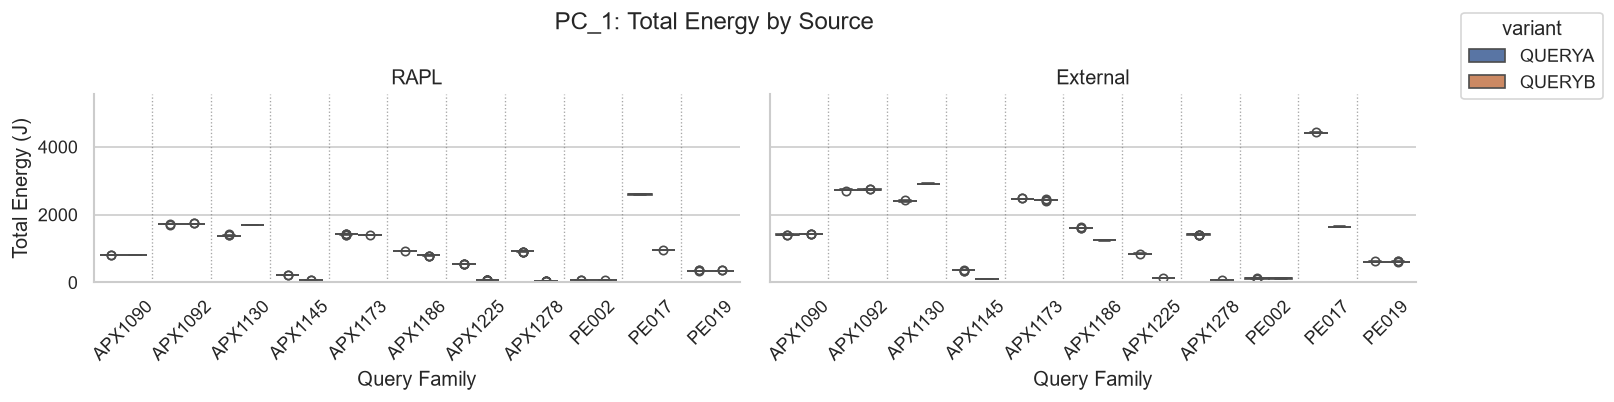

Saved: plots\ab_total_energy_boxplot_PC_2.svg


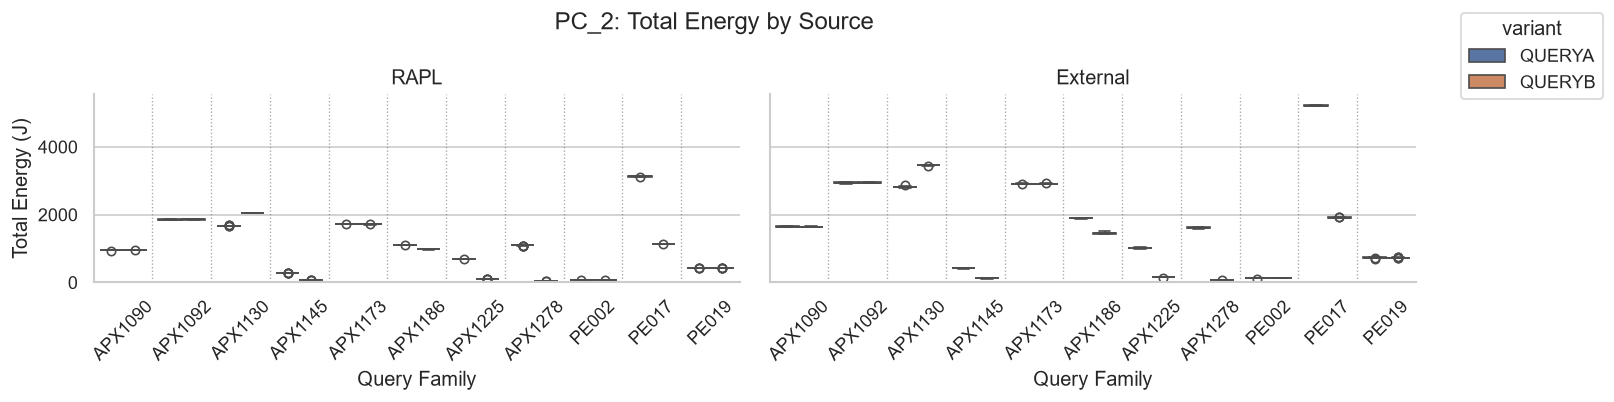

Saved: plots\ab_external_energy_pc_side_by_side.svg


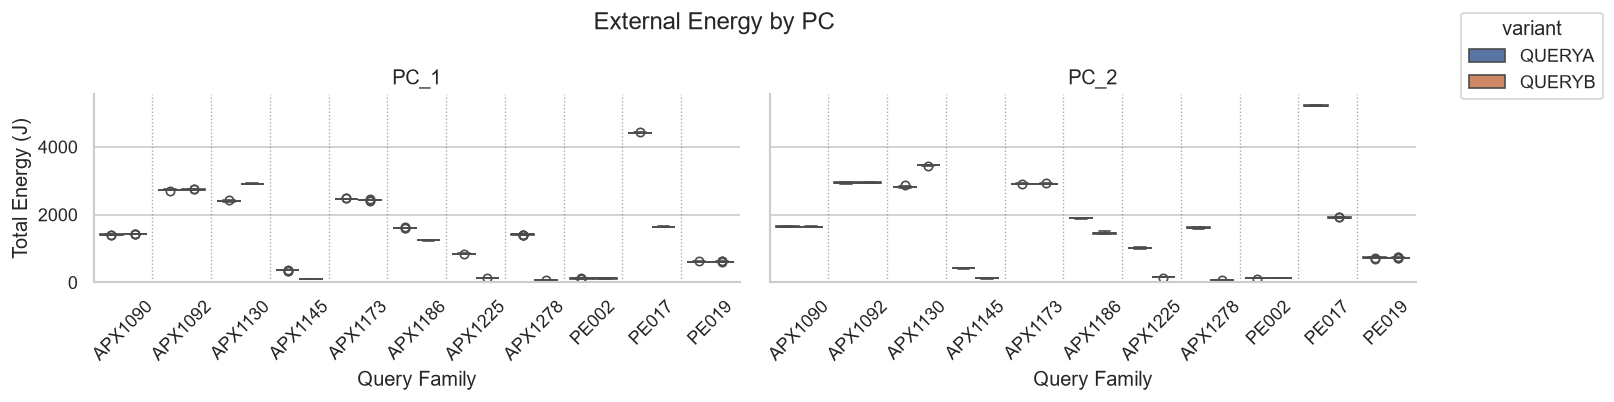

Saved: plots\ab_runtime_boxplot_PC_1.svg


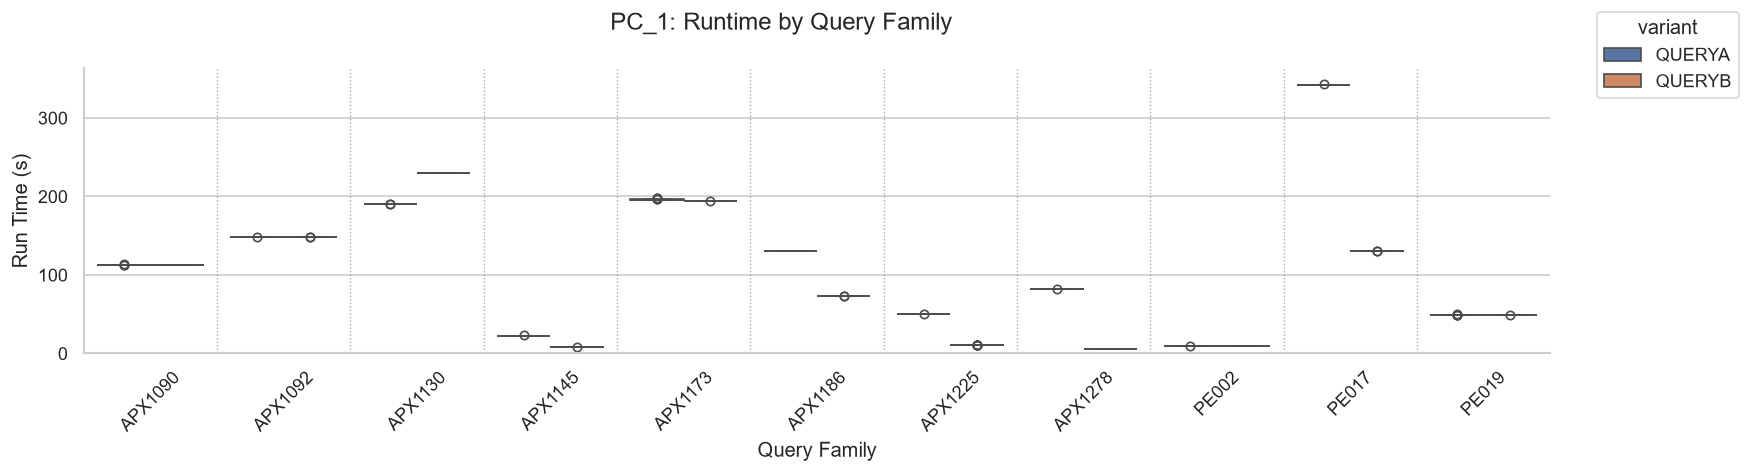

Saved: plots\ab_runtime_boxplot_PC_2.svg


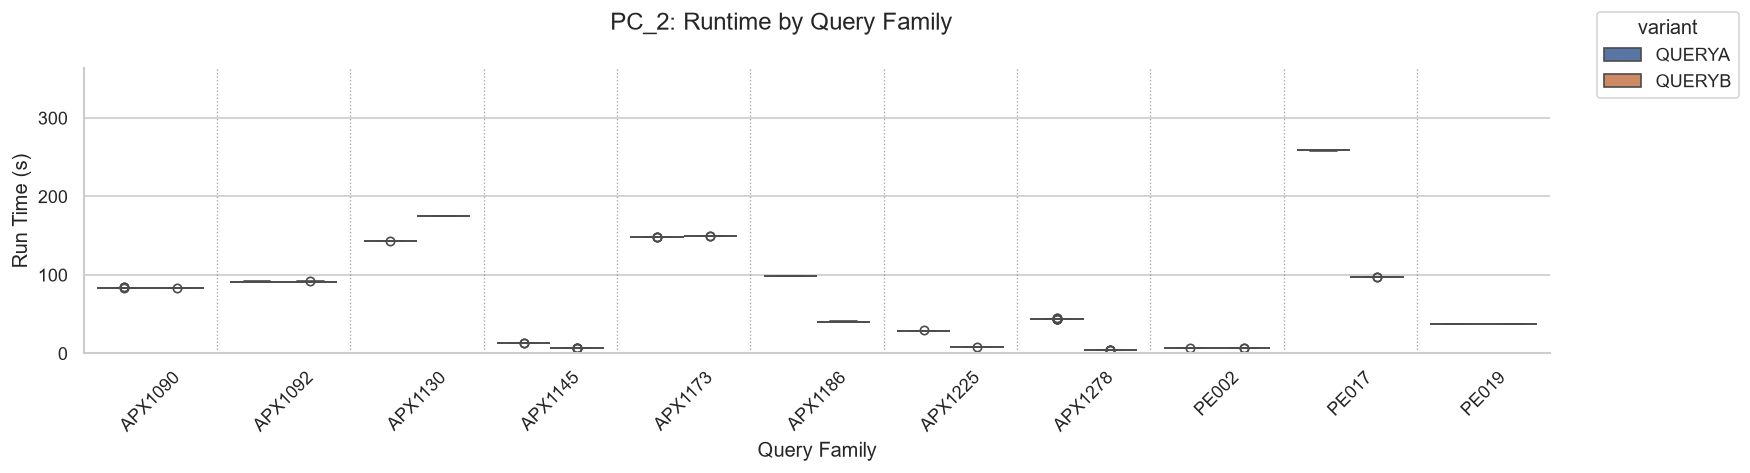

Saved: plots\ab_runtime_pc_side_by_side.svg


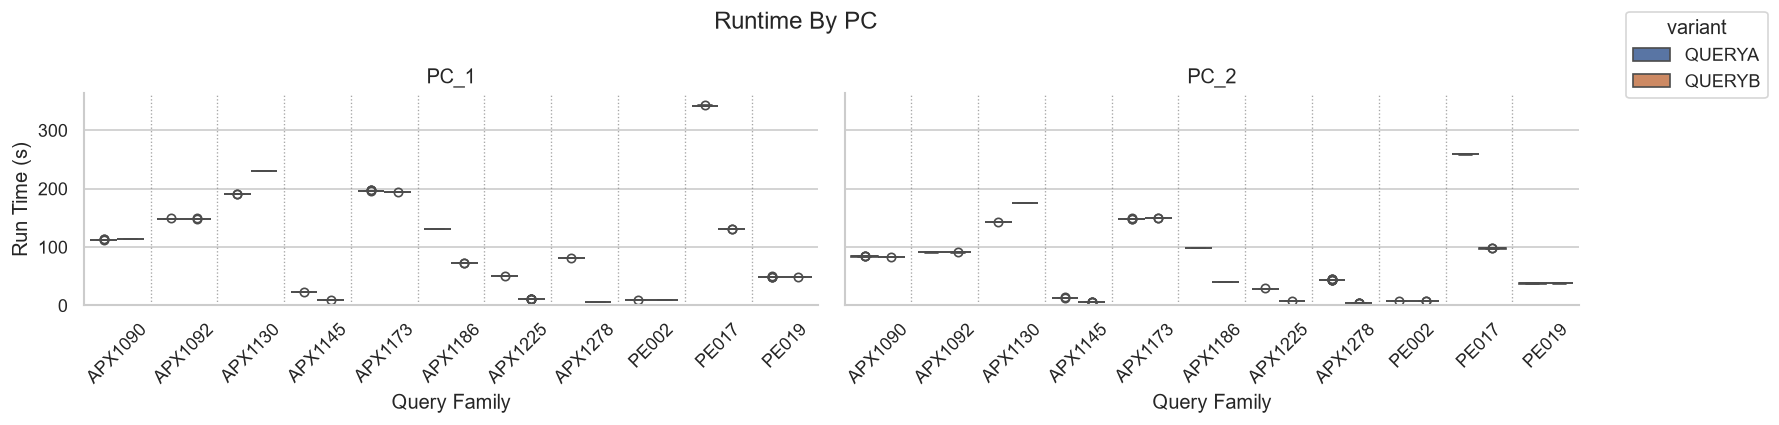

In [8]:
# Total Energy plot: A/B side-by-side with both RAPL and External shown.
from pathlib import Path

save_dir = Path("plots")
save_dir.mkdir(parents=True, exist_ok=True)

energy_long = plot_df.melt(
    id_vars=["pc", "query_family", "variant"],
    value_vars=["rapl_package_j", "external_energy_j"],
    var_name="source_metric",
    value_name="energy_j",
)
energy_long["source"] = energy_long["source_metric"].map({
    "rapl_package_j": "RAPL",
    "external_energy_j": "External",
})
energy_long = energy_long.dropna(subset=["energy_j", "query_family", "variant", "source", "pc"])

def _add_headroom(y_max: float | None, pad_ratio: float = 0.06) -> float | None:
    if y_max is None or not np.isfinite(y_max):
        return None
    return y_max * (1.0 + pad_ratio)

energy_ymax_raw = float(np.nanmax(energy_long["energy_j"])) if not energy_long.empty else None
energy_ymax = _add_headroom(energy_ymax_raw)

if energy_long.empty:
    print("No data available for energy plotting.")
else:
    for pc_name in ["PC_1", "PC_2"]:
        pc_energy = energy_long[energy_long["pc"] == pc_name].copy()
        if pc_energy.empty:
            continue
        g = sns.catplot(
            data=pc_energy,
            x="query_family",
            y="energy_j",
            hue="variant",
            col="source",
            col_order=["RAPL", "External"],
            order=query_order,
            kind="box",
            height=3.4,
            aspect=1.6,
            sharey=True,
        )
        g.set_axis_labels("Query Family", "Total Energy (J)")
        g.set_titles(col_template="{col_name}")
        for ax in g.axes.flat:
            ax.tick_params(axis="x", rotation=45)
        add_query_dividers(g, len(query_order))
        if energy_ymax is not None and np.isfinite(energy_ymax):
            g.set(ylim=(0, energy_ymax))
        sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, title="variant")
        g.figure.subplots_adjust(right=0.86)
        g.figure.suptitle(f"{pc_name}: Total Energy by Source")
        plt.tight_layout()
        out_path = save_dir / f"ab_total_energy_boxplot_{pc_name}.svg"
        g.figure.savefig(out_path, format="svg", bbox_inches="tight")
        print(f"Saved: {out_path}")
        plt.show()

# External Energy plot: PC1/PC2 side-by-side.
external_energy = energy_long[energy_long["source"] == "External"].copy()
if external_energy.empty:
    print("No data available for external energy plotting.")
else:
    g = sns.catplot(
        data=external_energy,
        x="query_family",
        y="energy_j",
        hue="variant",
        col="pc",
        col_order=["PC_1", "PC_2"],
        order=query_order,
        kind="box",
        height=3.4,
        aspect=1.6,
        sharey=True,
    )
    g.set_axis_labels("Query Family", "Total Energy (J)")
    g.set_titles(col_template="{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    if energy_ymax is not None and np.isfinite(energy_ymax):
        g.set(ylim=(0, energy_ymax))
    sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, title="variant")
    g.figure.subplots_adjust(right=0.86)
    g.figure.suptitle("External Energy by PC")
    plt.tight_layout()
    out_path = save_dir / "ab_external_energy_pc_side_by_side.svg"
    g.figure.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()

# Runtime plot: A/B side-by-side per query family, split by PC.
runtime_df = plot_df.dropna(subset=["total_elapsed_sec", "query_family", "variant", "pc"])
runtime_ymax_raw = float(np.nanmax(runtime_df["total_elapsed_sec"])) if not runtime_df.empty else None
runtime_ymax = _add_headroom(runtime_ymax_raw)

if runtime_df.empty:
    print("No data available for runtime plotting.")
else:
    for pc_name in ["PC_1", "PC_2"]:
        pc_runtime = runtime_df[runtime_df["pc"] == pc_name].copy()
        if pc_runtime.empty:
            continue
        g = sns.catplot(
            data=pc_runtime,
            x="query_family",
            y="total_elapsed_sec",
            hue="variant",
            order=query_order,
            kind="box",
            height=4.0,
            aspect=3.0,
            sharey=True,
        )
        g.set_axis_labels("Query Family", "Run Time (s)")
        g.set_titles("")
        for ax in g.axes.flat:
            ax.tick_params(axis="x", rotation=45)
        add_query_dividers(g, len(query_order))
        if runtime_ymax is not None and np.isfinite(runtime_ymax):
            g.set(ylim=(0, runtime_ymax))
        sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, title="variant")
        g.figure.subplots_adjust(right=0.86)
        g.figure.suptitle(f"{pc_name}: Runtime by Query Family")
        plt.tight_layout()
        out_path = save_dir / f"ab_runtime_boxplot_{pc_name}.svg"
        g.figure.savefig(out_path, format="svg", bbox_inches="tight")
        print(f"Saved: {out_path}")
        plt.show()

# Runtime plot: PC1/PC2 side-by-side.
if runtime_df.empty:
    print("No data available for runtime PC side-by-side plotting.")
else:
    g = sns.catplot(
        data=runtime_df,
        x="query_family",
        y="total_elapsed_sec",
        hue="variant",
        col="pc",
        col_order=["PC_1", "PC_2"],
        order=query_order,
        kind="box",
        height=3.6,
        aspect=1.7,
        sharey=True,
    )
    g.set_axis_labels("Query Family", "Run Time (s)")
    g.set_titles(col_template="{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    if runtime_ymax is not None and np.isfinite(runtime_ymax):
        g.set(ylim=(0, runtime_ymax))
    sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, title="variant")
    g.figure.subplots_adjust(right=0.86)
    g.figure.suptitle("Runtime By PC")
    plt.tight_layout()
    out_path = save_dir / "ab_runtime_pc_side_by_side.svg"
    g.figure.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()

Saved: plots\within_run_power_profile_PC_1.svg


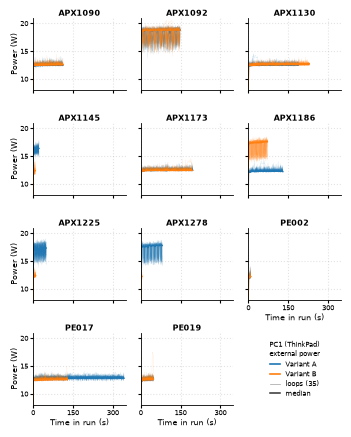

Saved: plots\within_run_power_profile_PC_2.svg


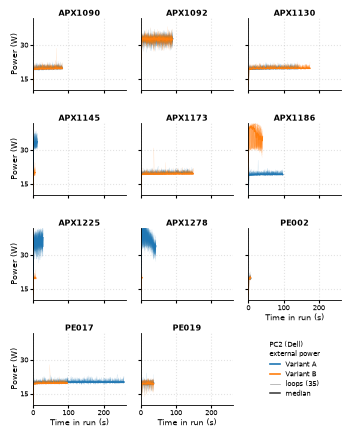

In [9]:
# Within-run power profile over time (external/sigless): one panel per query family for each PC.
def build_external_power_trace(sigless_file: Path, run_id_filter: str, pc_name: str, overflow=None) -> pd.DataFrame:
    trace_rows = []
    active_run = None
    active_power_rows = []

    with sigless_file.open("r", newline="", encoding="utf-8") as handle:
        reader = csv.reader(handle)
        _ = next(reader, None)

        for row in reader:
            if len(row) < 4:
                continue

            ts_raw, _channel, action, payload = row[0], row[1], row[2].strip(), row[3]
            try:
                timestamp = int(ts_raw)
            except ValueError:
                continue

            if action == "MESSAGE":
                msg = parse_message_payload(payload)
                msg_action = msg.get("action")

                if msg_action == "start":
                    if str(msg.get("run_id", "")) != str(run_id_filter):
                        continue

                    active_run = {
                        "run_id": str(msg.get("run_id")),
                        "test_name": msg.get("test"),
                        "loop_index": parse_loop_index(msg.get("loop")),
                    }
                    active_power_rows = []

                elif msg_action == "end" and active_run is not None:
                    power_df = pd.DataFrame(active_power_rows)
                    if power_df.shape[0] >= 2:
                        power_df = power_df.sort_values("timestamp").reset_index(drop=True)
                        power_df["power_w"] = add_overflow_power(power_df["timestamp"].to_numpy(), power_df["power_w"].to_numpy(), overflow)
                        power_df["time_s"] = (power_df["timestamp"] - power_df["timestamp"].iloc[0]) / 1000.0

                        trace_rows.append(pd.DataFrame({
                            "pc": pc_name,
                            "run_id": active_run["run_id"],
                            "test_name": active_run["test_name"],
                            "loop_index": active_run["loop_index"],
                            "timestamp": power_df["timestamp"].astype("int64").to_numpy(),
                            "time_s": power_df["time_s"].astype(float).to_numpy(),
                            "power_w": power_df["power_w"].astype(float).to_numpy(),
                        }))

                    active_run = None
                    active_power_rows = []

            elif action.startswith("POWER") and active_run is not None:
                try:
                    power_val = float(payload)
                except ValueError:
                    continue
                active_power_rows.append({"timestamp": timestamp, "power_w": power_val})

    traces = pd.concat(trace_rows, ignore_index=True) if trace_rows else pd.DataFrame()
    if traces.empty:
        return traces

    parsed = traces["test_name"].astype(str).apply(parse_test_name)
    traces["query_family"] = [p[0] for p in parsed]
    traces["variant"] = [p[1] for p in parsed]
    traces["loop_index"] = pd.to_numeric(traces["loop_index"], errors="coerce").astype("Int64")
    return traces


trace_frames = []
for pc_name, cfg in PCS.items():
    tdf = build_external_power_trace(cfg["sigless_file"], cfg["run_id"], pc_name, overflow=overflow_by_pc[pc_name])
    if not tdf.empty:
        trace_frames.append(tdf)

power_trace_df = pd.concat(trace_frames, ignore_index=True) if trace_frames else pd.DataFrame()
power_trace_df = power_trace_df[
    power_trace_df["variant"].isin(["QUERYA", "QUERYB"]) &
    power_trace_df["query_family"].notna() &
    power_trace_df["time_s"].notna() &
    power_trace_df["power_w"].notna()
].copy() if not power_trace_df.empty else power_trace_df

save_dir = Path("plots")
save_dir.mkdir(parents=True, exist_ok=True)

if power_trace_df.empty:
    print("No sample-level external traces available for within-run power plotting.")
else:
    pcs_order = [pc for pc in ["PC_1", "PC_2"] if pc in set(power_trace_df["pc"])]

    # Paper figure: one full-width figure per PC (analysis/figure_style.py)
    import importlib
    import figure_style as fs
    importlib.reload(fs)
    for pc_name in pcs_order:
        fs.power_profiles(power_trace_df, pc_name)


In [10]:
def ab_test_by_family(df: pd.DataFrame, value_col: str, metric_label: str, pc_name: str) -> list:
    rows = []
    fam_df = df[df["variant"].isin(["QUERYA", "QUERYB"]) & df["query_family"].notna()].copy()

    for family, g in fam_df.groupby("query_family"):
        a = g.loc[g["variant"] == "QUERYA", value_col].dropna().to_numpy()
        b = g.loc[g["variant"] == "QUERYB", value_col].dropna().to_numpy()

        n_a, n_b = len(a), len(b)
        if n_a < 2 or n_b < 2:
            continue

        shapiro_p_a = shapiro(a).pvalue if n_a >= 3 else np.nan
        shapiro_p_b = shapiro(b).pvalue if n_b >= 3 else np.nan
        normal_a = bool(shapiro_p_a > 0.05) if n_a >= 3 else False
        normal_b = bool(shapiro_p_b > 0.05) if n_b >= 3 else False

        if normal_a and normal_b:
            test_used = "welch_ttest"
            p_value = ttest_ind(a, b, equal_var=False).pvalue
            effect = (np.mean(a) - np.mean(b)) / np.sqrt(((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)) if n_a > 1 and n_b > 1 else np.nan
            effect_label = "std_mean_diff_A_minus_B"
        else:
            test_used = "mannwhitney_u"
            u = mannwhitneyu(a, b, alternative="two-sided").statistic
            p_value = mannwhitneyu(a, b, alternative="two-sided").pvalue
            effect = (2 * u / (n_a * n_b)) - 1
            effect_label = "rank_biserial_A_minus_B"

        rows.append({
            "pc": pc_name,
            "query_family": family,
            "metric": metric_label,
            "n_A": n_a,
            "n_B": n_b,
            "A_mean": float(np.mean(a)),
            "B_mean": float(np.mean(b)),
            "A_minus_B_mean": float(np.mean(a) - np.mean(b)),
            "A_vs_B_mean_pct": float(100 * (np.mean(a) - np.mean(b)) / np.mean(b)) if np.mean(b) != 0 else np.nan,
            "shapiro_p_A": shapiro_p_a,
            "shapiro_p_B": shapiro_p_b,
            "test_used": test_used,
            "p_value": p_value,
            "significant_0_05": bool(p_value < 0.05),
            "effect_label": effect_label,
            "effect_size": effect,
        })

    return rows


metrics_for_tests = [
    ("rapl_avg_power_w", "avg_power_rapl_w"),
    ("external_avg_power_w", "avg_power_external_w"),
    ("rapl_package_j", "energy_rapl_j"),
    ("external_energy_j", "energy_external_j"),
    ("total_elapsed_sec", "runtime_sec"),
]

stat_rows = []
for pc_name, payload in per_pc.items():
    mdf = payload["merged"]
    for col, label in metrics_for_tests:
        if col in mdf.columns:
            stat_rows.extend(ab_test_by_family(mdf, col, label, pc_name))

stats_df = pd.DataFrame(stat_rows)

if stats_df.empty:
    print("No family-level A/B statistical comparisons could be computed.")
else:
    stats_df = stats_df.sort_values(["pc", "metric", "query_family"]).reset_index(drop=True)
    print("A/B statistical test results by PC and query family:")
    display(
        stats_df[[
            "pc", "query_family", "metric", "n_A", "n_B", "test_used", "p_value",
            "significant_0_05", "A_mean", "B_mean", "A_vs_B_mean_pct", "effect_label", "effect_size"
        ]]
    )

    print("Significant results (p < 0.05):")
    display(
        stats_df.loc[stats_df["significant_0_05"]].sort_values(["pc", "metric", "p_value"])[[
            "pc", "query_family", "metric", "test_used", "p_value",
            "A_mean", "B_mean", "A_vs_B_mean_pct", "effect_label", "effect_size"
        ]]
    )

A/B statistical test results by PC and query family:


,pc,query_family,metric,n_A,n_B,test_used,p_value,significant_0_05,A_mean,B_mean,A_vs_B_mean_pct,effect_label,effect_size
0,PC_1,APX1090,avg_power_external_w,34,35,mannwhitney_u,4.574747e-08,True,12.555194,12.609253,-0.428725,rank_biserial_A_minus_B,-0.766387
1,PC_1,APX1092,avg_power_external_w,35,35,mannwhitney_u,3.870474e-02,True,18.382351,18.421192,-0.210853,rank_biserial_A_minus_B,-0.288163
2,PC_1,APX1130,avg_power_external_w,35,34,mannwhitney_u,4.605093e-05,True,12.592829,12.644567,-0.409174,rank_biserial_A_minus_B,-0.571429
3,PC_1,APX1145,avg_power_external_w,35,35,welch_ttest,9.466849e-63,True,15.921821,11.921155,33.559385,std_mean_diff_A_minus_B,21.438850
4,PC_1,APX1173,avg_power_external_w,35,35,mannwhitney_u,1.179774e-05,True,12.534658,12.515732,0.151220,rank_biserial_A_minus_B,0.609796
...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,PC_2,APX1225,runtime_sec,35,35,mannwhitney_u,6.545501e-13,True,28.827505,8.019325,259.475451,rank_biserial_A_minus_B,1.000000
106,PC_2,APX1278,runtime_sec,35,35,mannwhitney_u,6.545501e-13,True,44.000797,4.157910,958.243160,rank_biserial_A_minus_B,1.000000
107,PC_2,PE002,runtime_sec,35,35,mannwhitney_u,4.244445e-01,False,7.215738,7.209930,0.080551,rank_biserial_A_minus_B,0.111837
108,PC_2,PE017,runtime_sec,35,35,mannwhitney_u,6.545501e-13,True,258.588890,97.438315,165.387277,rank_biserial_A_minus_B,1.000000


Significant results (p < 0.05):


,pc,query_family,metric,test_used,p_value,A_mean,B_mean,A_vs_B_mean_pct,effect_label,effect_size
6,PC_1,APX1225,avg_power_external_w,welch_ttest,5.986310e-70,16.927308,12.026718,40.747528,std_mean_diff_A_minus_B,33.146217
3,PC_1,APX1145,avg_power_external_w,welch_ttest,9.466849e-63,15.921821,11.921155,33.559385,std_mean_diff_A_minus_B,21.438850
9,PC_1,PE017,avg_power_external_w,welch_ttest,9.590916e-50,12.907722,12.606519,2.389262,std_mean_diff_A_minus_B,11.158007
5,PC_1,APX1186,avg_power_external_w,mannwhitney_u,6.545501e-13,12.344193,17.000985,-27.391306,rank_biserial_A_minus_B,-1.000000
7,PC_1,APX1278,avg_power_external_w,mannwhitney_u,6.545501e-13,17.300410,11.501193,50.422747,rank_biserial_A_minus_B,1.000000
...,...,...,...,...,...,...,...,...,...,...
105,PC_2,APX1225,runtime_sec,mannwhitney_u,6.545501e-13,28.827505,8.019325,259.475451,rank_biserial_A_minus_B,1.000000
106,PC_2,APX1278,runtime_sec,mannwhitney_u,6.545501e-13,44.000797,4.157910,958.243160,rank_biserial_A_minus_B,1.000000
108,PC_2,PE017,runtime_sec,mannwhitney_u,6.545501e-13,258.588890,97.438315,165.387277,rank_biserial_A_minus_B,1.000000
99,PC_2,APX1090,runtime_sec,mannwhitney_u,7.132946e-13,83.768753,83.504362,0.316620,rank_biserial_A_minus_B,0.998367


In [11]:
# Cross-PC rank test: compare ranking of family-level A-B effects between PCs.
# Also includes a filtered Spearman test on families where |A-B|/B > 10% in external energy.
rank_rows = []


def get_energy_filter_families_for_rank(per_pc_dict: dict, threshold_pct: float = 10.0):
    keep = set()

    for pc_name, payload in per_pc_dict.items():
        mdf = payload["merged"]
        if "external_energy_j" not in mdf.columns:
            continue

        subset = mdf[mdf["variant"].isin(["QUERYA", "QUERYB"]) & mdf["query_family"].notna()].copy()
        fam = subset.groupby(["query_family", "variant"])["external_energy_j"].median().unstack()

        if not {"QUERYA", "QUERYB"}.issubset(fam.columns):
            continue

        fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
        fam["ab_energy_diff_pct"] = np.where(
            fam["QUERYB"] != 0,
            (fam["QUERYA"] - fam["QUERYB"]) / fam["QUERYB"] * 100,
            np.nan,
        )

        qualifying = fam.index[fam["ab_energy_diff_pct"].abs() > threshold_pct]
        keep.update(list(qualifying))

    return keep


energy_filter_families_for_rank = get_energy_filter_families_for_rank(per_pc, threshold_pct=10.0)

for col, label in metrics_for_tests:
    per_pc_effect = []
    for pc_name, payload in per_pc.items():
        mdf = payload["merged"]
        subset = mdf[mdf["variant"].isin(["QUERYA", "QUERYB"]) & mdf["query_family"].notna()].copy()
        fam = subset.groupby(["query_family", "variant"])[col].median().unstack()
        if "QUERYA" in fam.columns and "QUERYB" in fam.columns:
            fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
            fam["delta_A_minus_B"] = fam["QUERYA"] - fam["QUERYB"]
            fam = fam[["delta_A_minus_B"]].rename(columns={"delta_A_minus_B": pc_name})
            per_pc_effect.append(fam)

    if len(per_pc_effect) < 2:
        continue

    joined = per_pc_effect[0]
    for other in per_pc_effect[1:]:
        joined = joined.join(other, how="inner")

    if {"PC_1", "PC_2"}.issubset(joined.columns) and len(joined) >= 3:
        rho, p = spearmanr(joined["PC_1"], joined["PC_2"])

        filtered_joined = joined.loc[joined.index.intersection(list(energy_filter_families_for_rank))].copy()
        filtered_n = len(filtered_joined)

        if filtered_n >= 3:
            f_rho, f_p = spearmanr(filtered_joined["PC_1"], filtered_joined["PC_2"])
            f_same_signal = bool((f_rho > 0) and (f_p < 0.05))
            f_note = "ok"
        else:
            f_rho, f_p = np.nan, np.nan
            f_same_signal = False
            f_note = "insufficient_filtered_families"

        rank_rows.append({
            "metric": label,
            "n_query_families": int(len(joined)),
            "spearman_rho": float(rho),
            "p_value": float(p),
            "same_ranking_signal": bool((rho > 0) and (p < 0.05)),
            "filtered_n_query_families": int(filtered_n),
            "filtered_spearman_rho": float(f_rho) if not np.isnan(f_rho) else np.nan,
            "filtered_p_value": float(f_p) if not np.isnan(f_p) else np.nan,
            "filtered_same_ranking_signal": f_same_signal,
            "filtered_note": f_note,
        })

rank_df = pd.DataFrame(rank_rows)

if rank_df.empty:
    print("Not enough overlap to run cross-PC rank tests.")
else:
    print("Cross-PC rank agreement test (Spearman) on family-level A-B deltas:")
    print("Includes filtered Spearman result for families with |A-B|/B > 10% in external energy.")
    display(rank_df.sort_values("metric"))

# External vs RAPL rank test: within each PC and query variant, compare family rankings
# between external energy and RAPL package energy.
ext_rapl_rank_rows = []

for pc_name, payload in per_pc.items():
    mdf = payload["merged"]
    required_cols = {"query_family", "variant", "external_energy_j", "rapl_package_j"}
    if not required_cols.issubset(set(mdf.columns)):
        continue

    subset = mdf[
        mdf["variant"].isin(["QUERYA", "QUERYB"]) &
        mdf["query_family"].notna()
    ].copy()

    for variant in ["QUERYA", "QUERYB"]:
        variant_df = subset[subset["variant"] == variant].copy()
        fam = variant_df.groupby("query_family")[["external_energy_j", "rapl_package_j"]].median().dropna()
        n_fam = int(len(fam))

        if n_fam >= 3:
            rho, p = spearmanr(fam["external_energy_j"], fam["rapl_package_j"])
            note = "ok"
            same_signal = bool((rho > 0) and (p < 0.05))
            rho_val = float(rho)
            p_val = float(p)
        else:
            rho_val = np.nan
            p_val = np.nan
            same_signal = False
            note = "insufficient_families"

        ext_rapl_rank_rows.append({
            "pc": pc_name,
            "query": variant,
            "n_query_families": n_fam,
            "spearman_rho": rho_val,
            "p_value": p_val,
            "same_ranking_signal": same_signal,
            "note": note,
        })

ext_rapl_rank_df = pd.DataFrame(ext_rapl_rank_rows)

if ext_rapl_rank_df.empty:
    print("Not enough overlap to run external-vs-RAPL rank tests.")
else:
    print("External vs RAPL rank agreement test (Spearman) by PC and query variant:")
    display(ext_rapl_rank_df.sort_values(["pc", "query"]))


Cross-PC rank agreement test (Spearman) on family-level A-B deltas:
Includes filtered Spearman result for families with |A-B|/B > 10% in external energy.


,metric,n_query_families,spearman_rho,p_value,same_ranking_signal,filtered_n_query_families,filtered_spearman_rho,filtered_p_value,filtered_same_ranking_signal,filtered_note
1,avg_power_external_w,11,0.900000,0.000160,True,6,1.000000,0.000000,True,ok
0,avg_power_rapl_w,11,0.909091,0.000106,True,6,1.000000,0.000000,True,ok
3,energy_external_j,11,0.936364,0.000022,True,6,1.000000,0.000000,True,ok
2,energy_rapl_j,11,0.945455,0.000011,True,6,1.000000,0.000000,True,ok
4,runtime_sec,11,0.818182,0.002083,True,6,0.942857,0.004805,True,ok


External vs RAPL rank agreement test (Spearman) by PC and query variant:


,pc,query,n_query_families,spearman_rho,p_value,same_ranking_signal,note
0,PC_1,QUERYA,11,0.990909,3.762572e-09,True,ok
1,PC_1,QUERYB,11,0.990909,3.762572e-09,True,ok
2,PC_2,QUERYA,11,0.990909,3.762572e-09,True,ok
3,PC_2,QUERYB,11,0.990909,3.762572e-09,True,ok


In [12]:
# External vs RAPL on A/B family deltas: do both methods rank family-level A/B effects similarly?
ab_ext_vs_rapl_rank_rows = []

for pc_name, payload in per_pc.items():
    mdf = payload["merged"]
    required_cols = {"query_family", "variant", "external_energy_j", "rapl_package_j"}
    if not required_cols.issubset(set(mdf.columns)):
        continue

    subset = mdf[
        mdf["variant"].isin(["QUERYA", "QUERYB"]) &
        mdf["query_family"].notna()
    ].copy()

    # Family-level A/B deltas for each measurement source
    ext_fam = subset.groupby(["query_family", "variant"])["external_energy_j"].median().unstack()
    rapl_fam = subset.groupby(["query_family", "variant"])["rapl_package_j"].median().unstack()

    if not {"QUERYA", "QUERYB"}.issubset(ext_fam.columns) or not {"QUERYA", "QUERYB"}.issubset(rapl_fam.columns):
        continue

    ext_fam = ext_fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
    rapl_fam = rapl_fam.dropna(subset=["QUERYA", "QUERYB"]).copy()

    ext_fam["external_delta_A_minus_B"] = ext_fam["QUERYA"] - ext_fam["QUERYB"]
    rapl_fam["rapl_delta_A_minus_B"] = rapl_fam["QUERYA"] - rapl_fam["QUERYB"]

    joined = ext_fam[["external_delta_A_minus_B"]].join(
        rapl_fam[["rapl_delta_A_minus_B"]],
        how="inner"
    ).dropna()

    n_fam = int(len(joined))
    if n_fam >= 3:
        rho, p = spearmanr(joined["external_delta_A_minus_B"], joined["rapl_delta_A_minus_B"])
        note = "ok"
        same_signal = bool((rho > 0) and (p < 0.05))
        rho_val = float(rho)
        p_val = float(p)
    else:
        rho_val = np.nan
        p_val = np.nan
        same_signal = False
        note = "insufficient_families"

    # Median signed offset of A/B deltas across families
    median_delta_offset_j = float(np.median(
        joined["external_delta_A_minus_B"] - joined["rapl_delta_A_minus_B"]
    )) if n_fam > 0 else np.nan

    ab_ext_vs_rapl_rank_rows.append({
        "pc": pc_name,
        "n_query_families": n_fam,
        "spearman_rho": rho_val,
        "p_value": p_val,
        "same_ranking_signal": same_signal,
        "median_external_minus_rapl_delta_j": median_delta_offset_j,
        "note": note,
    })

ab_ext_vs_rapl_rank_df = pd.DataFrame(ab_ext_vs_rapl_rank_rows)

if ab_ext_vs_rapl_rank_df.empty:
    print("Not enough overlap to run external-vs-RAPL A/B-delta rank tests.")
else:
    print("External vs RAPL rank agreement on family-level A/B deltas (QUERYA - QUERYB), by PC:")
    display(ab_ext_vs_rapl_rank_df.sort_values("pc"))


External vs RAPL rank agreement on family-level A/B deltas (QUERYA - QUERYB), by PC:


,pc,n_query_families,spearman_rho,p_value,same_ranking_signal,median_external_minus_rapl_delta_j,note
0,PC_1,11,0.990909,3.762572e-09,True,8.480713,ok
1,PC_2,11,0.981818,8.403066e-08,True,2.836056,ok


In [13]:
from scipy.stats import wilcoxon

# Cross-PC consistency test: are A/B deltas similar between PCs?
# Uses Wilcoxon signed-rank on paired family-level deltas: (QUERYA - QUERYB) in PC_1 vs PC_2.
# Also reports a second statistic on a filtered subset: families where |A-B|/B > 10% for external energy.


def run_paired_wilcoxon(x: pd.Series, y: pd.Series):
    d = (x - y).to_numpy()
    if len(d) == 0:
        return np.nan, np.nan, "no_pairs"
    if np.allclose(d, 0):
        return np.nan, np.nan, "all_paired_differences_zero"

    res = wilcoxon(x, y, alternative="two-sided")
    return float(res.statistic), float(res.pvalue), "ok"


def get_energy_filter_families(per_pc_dict: dict, energy_col: str = "external_energy_j", threshold_pct: float = 10.0):
    keep = set()

    for pc_name, payload in per_pc_dict.items():
        mdf = payload["merged"]
        if energy_col not in mdf.columns:
            continue

        subset = mdf[mdf["variant"].isin(["QUERYA", "QUERYB"]) & mdf["query_family"].notna()].copy()
        fam = subset.groupby(["query_family", "variant"])[energy_col].median().unstack()

        if not {"QUERYA", "QUERYB"}.issubset(fam.columns):
            continue

        fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
        fam["ab_energy_diff_pct"] = np.where(
            fam["QUERYB"] != 0,
            (fam["QUERYA"] - fam["QUERYB"]) / fam["QUERYB"] * 100,
            np.nan,
        )

        qualifying = fam.index[fam["ab_energy_diff_pct"].abs() > threshold_pct]
        keep.update(list(qualifying))

    return keep


energy_filter_families = get_energy_filter_families(per_pc, energy_col="external_energy_j", threshold_pct=10.0)
consistency_rows = []

for col, label in metrics_for_tests:
    per_pc_delta = []

    for pc_name, payload in per_pc.items():
        mdf = payload["merged"]
        if col not in mdf.columns:
            continue

        subset = mdf[mdf["variant"].isin(["QUERYA", "QUERYB"]) & mdf["query_family"].notna()].copy()
        fam = subset.groupby(["query_family", "variant"])[col].median().unstack()

        if {"QUERYA", "QUERYB"}.issubset(fam.columns):
            fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
            fam["delta_A_minus_B"] = fam["QUERYA"] - fam["QUERYB"]
            per_pc_delta.append(fam[["delta_A_minus_B"]].rename(columns={"delta_A_minus_B": pc_name}))

    if len(per_pc_delta) < 2:
        continue

    joined = per_pc_delta[0]
    for other in per_pc_delta[1:]:
        joined = joined.join(other, how="inner")

    if not {"PC_1", "PC_2"}.issubset(joined.columns):
        continue

    joined = joined.dropna(subset=["PC_1", "PC_2"]).copy()
    n = len(joined)
    if n == 0:
        continue

    stat, p_value, note = run_paired_wilcoxon(joined["PC_1"], joined["PC_2"])

    # Second statistic on filtered families with >10% A/B external-energy difference.
    filtered_joined = joined.loc[joined.index.intersection(list(energy_filter_families))].copy()
    filtered_n = len(filtered_joined)

    if filtered_n == 0:
        f_stat, f_p_value, f_note = np.nan, np.nan, "no_families_pass_energy_filter"
        f_consistent = False
        f_median_diff = np.nan
    else:
        f_stat, f_p_value, f_note = run_paired_wilcoxon(filtered_joined["PC_1"], filtered_joined["PC_2"])
        f_consistent = bool((not np.isnan(f_p_value)) and (f_p_value >= 0.05))
        f_median_diff = float(np.median((filtered_joined["PC_1"] - filtered_joined["PC_2"]).to_numpy()))

    consistency_rows.append({
        "metric": label,
        "n_query_families": int(n),
        "pc1_delta_median": float(np.median(joined["PC_1"])),
        "pc2_delta_median": float(np.median(joined["PC_2"])),
        "median_of_paired_diff_pc1_minus_pc2": float(np.median((joined["PC_1"] - joined["PC_2"]).to_numpy())),
        "wilcoxon_statistic": stat,
        "p_value": p_value,
        "consistent_ab_delta_0_05": bool((not np.isnan(p_value)) and (p_value >= 0.05)),
        "note": note,
        "filtered_n_query_families": int(filtered_n),
        "filtered_median_of_paired_diff_pc1_minus_pc2": f_median_diff,
        "filtered_wilcoxon_statistic": f_stat,
        "filtered_p_value": f_p_value,
        "filtered_consistent_ab_delta_0_05": f_consistent,
        "filtered_note": f_note,
    })

consistency_df = pd.DataFrame(consistency_rows)

if consistency_df.empty:
    print("Not enough overlapping family deltas to run cross-PC Wilcoxon consistency tests.")
else:
    print("Wilcoxon signed-rank consistency test on family-level A/B deltas (PC_1 vs PC_2):")
    print("Second statistic uses only families where |A-B|/B > 10% in external energy (in either PC).")
    display(consistency_df.sort_values("metric"))

    print("Interpretation guide: p >= 0.05 means no evidence that PC_1 and PC_2 A/B deltas differ systematically.")

Wilcoxon signed-rank consistency test on family-level A/B deltas (PC_1 vs PC_2):
Second statistic uses only families where |A-B|/B > 10% in external energy (in either PC).


,metric,n_query_families,pc1_delta_median,pc2_delta_median,median_of_paired_diff_pc1_minus_pc2,wilcoxon_statistic,p_value,consistent_ab_delta_0_05,note,filtered_n_query_families,filtered_median_of_paired_diff_pc1_minus_pc2,filtered_wilcoxon_statistic,filtered_p_value,filtered_consistent_ab_delta_0_05,filtered_note
1,avg_power_external_w,11,-0.024550,0.085607,-0.128016,13.0,0.083008,True,ok,6,-4.795472,5.0,0.31250,True,ok
0,avg_power_rapl_w,11,-0.006434,0.018571,-0.060301,16.0,0.147461,True,ok,6,-3.770608,6.0,0.43750,True,ok
3,energy_external_j,11,26.669800,8.694680,-22.252120,13.0,0.083008,True,ok,6,-109.180015,3.0,0.15625,True,ok
2,energy_rapl_j,11,18.189087,12.551392,-0.229523,20.0,0.278320,True,ok,6,-86.605499,4.0,0.21875,True,ok
4,runtime_sec,11,1.643034,0.225169,0.003310,21.0,0.320312,True,ok,6,12.786109,4.0,0.21875,True,ok


Interpretation guide: p >= 0.05 means no evidence that PC_1 and PC_2 A/B deltas differ systematically.


In [14]:
if not stats_df.empty:
    sig_counts = (
        stats_df.groupby(["pc", "metric"], as_index=False)["significant_0_05"]
        .sum()
        .rename(columns={"significant_0_05": "n_significant_families"})
    )
    print("Significant A/B families per PC and metric (p < 0.05):")
    display(sig_counts.sort_values(["pc", "metric"]))

if not rank_df.empty:
    print("Cross-PC rank agreement summary:")
    display(rank_df.sort_values("metric"))

Significant A/B families per PC and metric (p < 0.05):


,pc,metric,n_significant_families
0,PC_1,avg_power_external_w,10
1,PC_1,avg_power_rapl_w,9
2,PC_1,energy_external_j,9
3,PC_1,energy_rapl_j,10
4,PC_1,runtime_sec,9
5,PC_2,avg_power_external_w,9
6,PC_2,avg_power_rapl_w,9
7,PC_2,energy_external_j,9
8,PC_2,energy_rapl_j,10
9,PC_2,runtime_sec,8


Cross-PC rank agreement summary:


,metric,n_query_families,spearman_rho,p_value,same_ranking_signal,filtered_n_query_families,filtered_spearman_rho,filtered_p_value,filtered_same_ranking_signal,filtered_note
1,avg_power_external_w,11,0.900000,0.000160,True,6,1.000000,0.000000,True,ok
0,avg_power_rapl_w,11,0.909091,0.000106,True,6,1.000000,0.000000,True,ok
3,energy_external_j,11,0.936364,0.000022,True,6,1.000000,0.000000,True,ok
2,energy_rapl_j,11,0.945455,0.000011,True,6,1.000000,0.000000,True,ok
4,runtime_sec,11,0.818182,0.002083,True,6,0.942857,0.004805,True,ok


In [15]:
from scipy.stats import wilcoxon, mannwhitneyu

# Wilcoxon signed-rank between PCs on per-test mean energy.
# Assumption: compare PC_1 vs PC_2 using paired test_name means for external energy.
energy_col = "external_energy_j"
threshold_pct = 10.0


def build_pc_test_means(per_pc_dict: dict, value_col: str) -> pd.DataFrame:
    frames = []
    for pc_name, payload in per_pc_dict.items():
        mdf = payload["merged"]
        if value_col not in mdf.columns:
            continue
        means = (
            mdf.groupby("test_name", as_index=False)[value_col]
            .mean()
            .rename(columns={value_col: pc_name})
        )
        frames.append(means)

    if len(frames) < 2:
        return pd.DataFrame()

    out = frames[0]
    for f in frames[1:]:
        out = out.merge(f, on="test_name", how="inner")
    return out


def ab_energy_diff_pct_by_pc(per_pc_dict: dict, value_col: str) -> pd.DataFrame:
    rows = []
    for pc_name, payload in per_pc_dict.items():
        mdf = payload["merged"]
        if value_col not in mdf.columns:
            continue

        subset = mdf[mdf["variant"].isin(["QUERYA", "QUERYB"]) & mdf["query_family"].notna()].copy()
        fam = subset.groupby(["query_family", "variant"])[value_col].mean().unstack()

        if "QUERYA" not in fam.columns or "QUERYB" not in fam.columns:
            continue

        fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
        fam["ab_diff_pct"] = np.where(
            fam["QUERYB"] != 0,
            (fam["QUERYA"] - fam["QUERYB"]) / fam["QUERYB"] * 100,
            np.nan,
        )

        fam = fam.reset_index()[["query_family", "ab_diff_pct"]]
        fam["pc"] = pc_name
        rows.append(fam)

    if not rows:
        return pd.DataFrame()

    return pd.concat(rows, ignore_index=True)


paired_energy = build_pc_test_means(per_pc, energy_col)

if paired_energy.empty or not {"PC_1", "PC_2"}.issubset(paired_energy.columns):
    print(f"Could not build paired PC data for {energy_col}.")
else:
    paired_energy = paired_energy.dropna(subset=["PC_1", "PC_2"]).copy()

    if len(paired_energy) == 0:
        print("No overlapping tests with non-null energy means between PCs.")
    else:
        # Baseline Wilcoxon signed-rank over all paired test names.
        all_res = wilcoxon(paired_energy["PC_1"], paired_energy["PC_2"], alternative="two-sided")
        all_ranksum = mannwhitneyu(paired_energy["PC_1"], paired_energy["PC_2"], alternative="two-sided")

        print(f"Wilcoxon signed-rank (all paired test names) for {energy_col}:")
        print(f"n_pairs = {len(paired_energy)}")
        print(f"statistic = {all_res.statistic:.6g}, p_value = {all_res.pvalue:.6g}")

        print("Wilcoxon rank-sum (Mann-Whitney U, all paired test names as two samples):")
        print(f"n_PC1 = {len(paired_energy['PC_1'])}, n_PC2 = {len(paired_energy['PC_2'])}")
        print(f"statistic = {all_ranksum.statistic:.6g}, p_value = {all_ranksum.pvalue:.6g}")

        # Subset by |A/B mean difference| > threshold_pct.
        ab_diff = ab_energy_diff_pct_by_pc(per_pc, energy_col)

        if ab_diff.empty:
            print("Could not compute A/B mean energy differences for subset filtering.")
        else:
            # Keep families where either PC shows > threshold in absolute terms.
            fam_keep = (
                ab_diff.assign(abs_ab_diff_pct=ab_diff["ab_diff_pct"].abs())
                .groupby("query_family", as_index=False)["abs_ab_diff_pct"]
                .max()
            )
            fam_keep = fam_keep.loc[fam_keep["abs_ab_diff_pct"] > threshold_pct, "query_family"]

            filtered = paired_energy.copy()
            filtered["query_family"] = filtered["test_name"].str.replace(r"-query[AB]\.sql$", "", regex=True)
            filtered = filtered[filtered["query_family"].isin(fam_keep)].drop(columns=["query_family"])

            print(
                f"\nFamilies passing |A/B mean energy diff| > {threshold_pct:.0f}%: {len(fam_keep)}"
            )
            print(f"Paired test names in filtered set: {len(filtered)}")

            if len(filtered) == 0:
                print("No paired tests left after filtering.")
            elif np.allclose(filtered["PC_1"].to_numpy(), filtered["PC_2"].to_numpy()):
                print("Filtered paired energies are identical between PCs; Wilcoxon signed-rank is undefined.")
                filt_ranksum = mannwhitneyu(filtered["PC_1"], filtered["PC_2"], alternative="two-sided")
                print("Wilcoxon rank-sum (Mann-Whitney U, filtered set):")
                print(f"statistic = {filt_ranksum.statistic:.6g}, p_value = {filt_ranksum.pvalue:.6g}")
            else:
                filt_res = wilcoxon(filtered["PC_1"], filtered["PC_2"], alternative="two-sided")
                filt_ranksum = mannwhitneyu(filtered["PC_1"], filtered["PC_2"], alternative="two-sided")
                print("Wilcoxon signed-rank (filtered set):")
                print(f"statistic = {filt_res.statistic:.6g}, p_value = {filt_res.pvalue:.6g}")
                print("Wilcoxon rank-sum (Mann-Whitney U, filtered set):")
                print(f"statistic = {filt_ranksum.statistic:.6g}, p_value = {filt_ranksum.pvalue:.6g}")

        # Optional inspection table
        display(paired_energy.sort_values("test_name").reset_index(drop=True))

Wilcoxon signed-rank (all paired test names) for external_energy_j:
n_pairs = 22
statistic = 0, p_value = 4.76837e-07
Wilcoxon rank-sum (Mann-Whitney U, all paired test names as two samples):
n_PC1 = 22, n_PC2 = 22
statistic = 201, p_value = 0.341786

Families passing |A/B mean energy diff| > 10%: 6
Paired test names in filtered set: 12
Wilcoxon signed-rank (filtered set):
statistic = 0, p_value = 0.000488281
Wilcoxon rank-sum (Mann-Whitney U, filtered set):
statistic = 64, p_value = 0.665006


,test_name,PC_1,PC_2
0,APX1090-queryA.sql,1410.222082,1648.060806
1,APX1090-queryB.sql,1424.863289,1640.442665
2,APX1092-queryA.sql,2732.796237,2938.954754
3,APX1092-queryB.sql,2738.777697,2946.626752
4,APX1130-queryA.sql,2396.558677,2814.630013
5,APX1130-queryB.sql,2907.002906,3452.849646
6,APX1145-queryA.sql,356.741786,417.915501
7,APX1145-queryB.sql,103.441449,120.868449
8,APX1173-queryA.sql,2459.268880,2913.662439
9,APX1173-queryB.sql,2431.786523,2907.234605


In [16]:
# Compute RAPL offset for each test and PC
offset_rows = []

for pc_name, payload in per_pc.items():
    mdf = payload["merged"]
    
    # Group by test_name to get per-test metrics
    for test_name, group in mdf.groupby("test_name"):
        rapl_avg_power = group["rapl_avg_power_w"].median()
        external_avg_power = group["external_avg_power_w"].median()
        
        rapl_energy = group["rapl_package_j"].median()
        external_energy = group["external_energy_j"].median()
        
        # Calculate percentage offsets
        power_offset_pct = (rapl_avg_power - external_avg_power) / external_avg_power * 100 if pd.notna(external_avg_power) and external_avg_power != 0 else np.nan
        energy_offset_pct = (rapl_energy - external_energy) / external_energy * 100 if pd.notna(external_energy) and external_energy != 0 else np.nan
        energy_offset_pct_standard_deviation = ((group["rapl_package_j"] - group["external_energy_j"]) / group["external_energy_j"] * 100).std() if "rapl_package_j" in group.columns and "external_energy_j" in group.columns else np.nan
        
        # Parse query family and variant
        family, variant = parse_test_name(test_name)
        
        offset_rows.append({
            "pc": pc_name,
            "test_name": test_name,
            "query_family": family,
            "variant": variant,
            "rapl_avg_power_w": rapl_avg_power if pd.notna(rapl_avg_power) else np.nan,
            "external_avg_power_w": external_avg_power if pd.notna(external_avg_power) else np.nan,
            "power_offset_pct": power_offset_pct,
            "rapl_energy_j": rapl_energy if pd.notna(rapl_energy) else np.nan,
            "external_energy_j": external_energy if pd.notna(external_energy) else np.nan,
            "energy_offset_pct": energy_offset_pct,
            "energy_offset_pct_standard_deviation": energy_offset_pct_standard_deviation,
            "n_runs": len(group),
        })

offset_df = pd.DataFrame(offset_rows)

if offset_df.empty:
    print("No offset data available.")
else:
    offset_df = offset_df.sort_values(["pc", "query_family", "variant"]).reset_index(drop=True)
    print("RAPL offset (% difference from external measurements) by test and PC:")
    display(offset_df[[
        "pc", "query_family", "variant", "test_name",
        "rapl_avg_power_w", "external_avg_power_w", "power_offset_pct",
        "rapl_energy_j", "external_energy_j", "energy_offset_pct", "energy_offset_pct_standard_deviation", "n_runs"
    ]])


RAPL offset (% difference from external measurements) by test and PC:


,pc,query_family,variant,test_name,rapl_avg_power_w,external_avg_power_w,power_offset_pct,rapl_energy_j,external_energy_j,energy_offset_pct,energy_offset_pct_standard_deviation,n_runs
0,PC_1,APX1090,QUERYA,APX1090-queryA.sql,7.166459,12.560861,-42.946118,805.192780,1410.123250,-42.899120,0.198060,34
1,PC_1,APX1090,QUERYB,APX1090-queryB.sql,7.208189,12.604966,-42.814685,814.804871,1425.152900,-42.826845,0.141325,35
2,PC_1,APX1092,QUERYA,APX1092-queryA.sql,11.654160,18.394021,-36.641586,1732.130249,2734.920900,-36.666167,0.157096,35
3,PC_1,APX1092,QUERYB,APX1092-queryB.sql,11.668820,18.421313,-36.655875,1735.185303,2738.805000,-36.644438,0.213402,35
4,PC_1,APX1130,QUERYA,APX1130-queryA.sql,7.250136,12.575416,-42.346751,1380.057739,2392.887900,-42.326687,0.217182,35
5,PC_1,APX1130,QUERYB,APX1130-queryB.sql,7.326922,12.644757,-42.055653,1684.433380,2906.675600,-42.049488,0.119787,34
6,PC_1,APX1145,QUERYA,APX1145-queryA.sql,10.000871,15.927146,-37.208642,224.137695,356.879800,-37.195186,0.762716,35
7,PC_1,APX1145,QUERYB,APX1145-queryB.sql,6.882874,11.918134,-42.248725,59.719360,103.586900,-42.348540,1.129530,35
8,PC_1,APX1173,QUERYA,APX1173-queryA.sql,7.213529,12.533388,-42.445497,1414.361694,2457.892000,-42.456312,0.092463,35
9,PC_1,APX1173,QUERYB,APX1173-queryB.sql,7.182440,12.510346,-42.587998,1396.172607,2431.222200,-42.573221,0.155833,35


Saved: plots\rapl_energy_offset_bars.svg

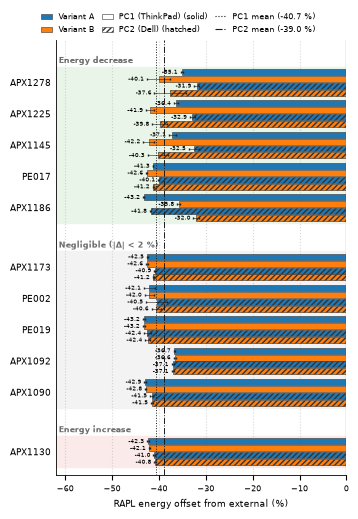


RAPL energy offset summary by PC and variant:


energy_offset_pct                                           
                          mean     median        min        max       std
variant pc                                                               
QUERYA  PC_1        -40.236607 -41.987764 -43.234100 -34.974894  3.201340
        PC_2        -38.477820 -40.866429 -42.555577 -31.936727  4.080410
QUERYB  PC_1        -41.135827 -42.128278 -43.266684 -35.705971  2.567068
        PC_2        -39.607002 -40.660692 -42.449397 -32.022329  2.933830


Energy offset pct difference between QueryA and QueryB by PC and query family:


variant,pc,query_family,queryA_energy_offset_pct,queryB_energy_offset_pct,energy_offset_pct_diff_pp
0,PC_1,APX1090,-42.899120,-42.826845,-0.072275
1,PC_1,APX1092,-36.666167,-36.644438,-0.021729
2,PC_1,APX1130,-42.326687,-42.049488,-0.277198
3,PC_1,APX1145,-37.195186,-42.348540,5.153354
4,PC_1,APX1173,-42.456312,-42.573221,0.116908
5,PC_1,APX1186,-43.234100,-35.705971,-7.528129
6,PC_1,APX1225,-36.411645,-41.991676,5.580031
7,PC_1,APX1278,-34.974894,-40.357613,5.382719
8,PC_1,PE002,-41.987764,-42.128278,0.140514
9,PC_1,PE017,-41.270184,-42.601345,1.331160


In [17]:
# Visualize RAPL energy offsets by PC and overall across all queries.
from pathlib import Path

if not offset_df.empty:
    plot_offset = offset_df.dropna(subset=["energy_offset_pct"]).copy()

    if plot_offset.empty:
        print("No energy offset data available for plotting.")
    else:
        # Paper figure: vertical bars, both PCs, A/B (analysis/figure_style.py)
        import importlib
        import figure_style as fs
        importlib.reload(fs)
        fs.offset_bars(analysis_df, stats_df, "rapl_energy_offset_bars")

        # Summary statistics
        print("\nRAPL energy offset summary by PC and variant:")
        summary = offset_df.groupby(["variant", "pc"])[["energy_offset_pct"]].agg([
            ("mean", "mean"),
            ("median", "median"),
            ("min", "min"),
            ("max", "max"),
            ("std", "std"),
        ])
        display(summary)

        paired_energy = offset_df[offset_df["variant"].isin(["QUERYA", "QUERYB"])].copy()
        if paired_energy.empty:
            print("No paired QueryA/QueryB energy offset data available.")
        else:
            paired_energy = (
                paired_energy.groupby(["pc", "query_family", "variant"], as_index=False)["energy_offset_pct"]
                .median()
                .pivot(index=["pc", "query_family"], columns="variant", values="energy_offset_pct")
                .reset_index()
            )
            paired_energy["energy_offset_pct_diff_pp"] = paired_energy["QUERYA"] - paired_energy["QUERYB"]
            paired_energy = paired_energy.sort_values(["pc", "query_family"]).reset_index(drop=True)
            print("\nEnergy offset pct difference between QueryA and QueryB by PC and query family:")
            display(paired_energy.rename(columns={"QUERYA": "queryA_energy_offset_pct", "QUERYB": "queryB_energy_offset_pct"}))

Saved: plots\pc_comparison_runtime_energy_energy_per_sec.svg


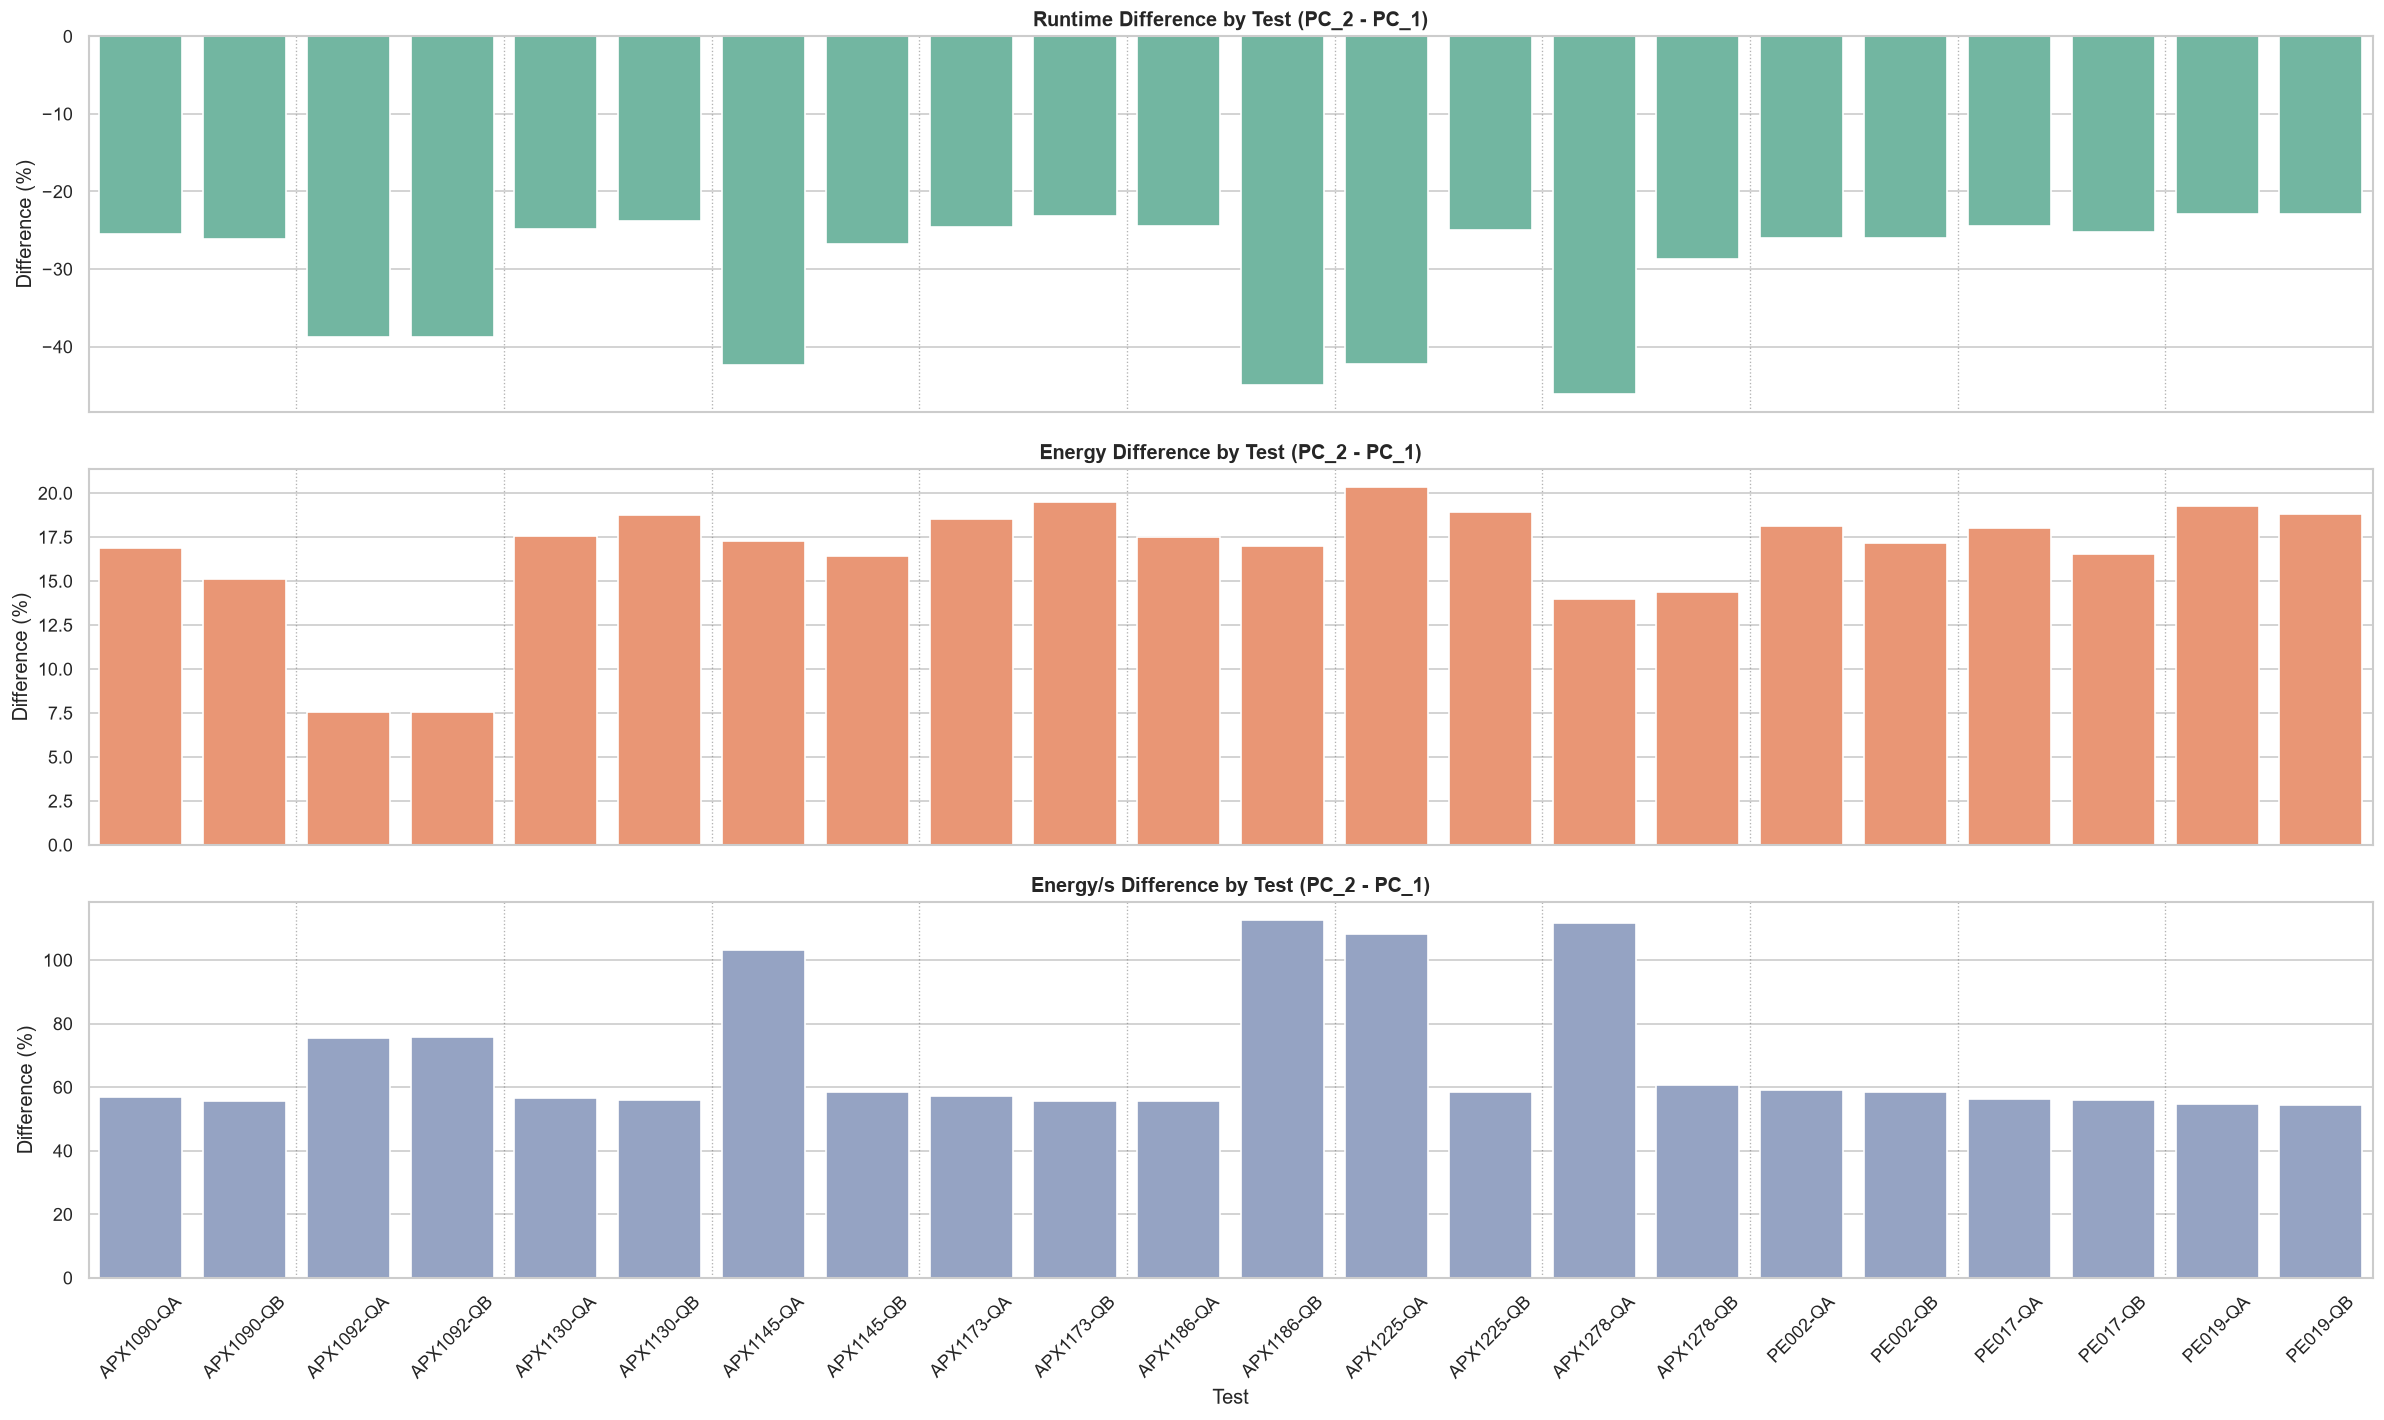

PC_1 vs PC_2 Comparison (median values by test):


,test_name,test_label,query_family,variant,pc1_runtime_sec,pc2_runtime_sec,runtime_diff_pct,pc1_energy_j,pc2_energy_j,energy_diff_pct,pc1_energy_per_sec,pc2_energy_per_sec,energy_per_sec_diff_pct
0,APX1090-queryA.sql,APX1090-QA,APX1090,QUERYA,112.358033,83.723207,-25.485339,1410.12325,1648.117760,16.877568,12.552045,19.680446,56.790755
1,APX1090-queryB.sql,APX1090-QB,APX1090,QUERYB,113.024325,83.498038,-26.123834,1425.15290,1640.895290,15.138193,12.606086,19.637130,55.775001
2,APX1092-queryA.sql,APX1092-QA,APX1092,QUERYA,148.664492,91.071326,-38.740364,2734.92090,2941.242060,7.543953,18.394310,32.271086,75.440587
3,APX1092-queryB.sql,APX1092-QB,APX1092,QUERYB,148.687960,90.969113,-38.818777,2738.80500,2945.129710,7.533384,18.420726,32.372171,75.737757
4,APX1130-queryA.sql,APX1130-QA,APX1130,QUERYA,190.330147,142.987840,-24.873783,2392.88790,2812.794540,17.548112,12.575889,19.673969,56.441975
5,APX1130-queryB.sql,APX1130-QB,APX1130,QUERYB,229.901675,175.007556,-23.877215,2906.67560,3452.505748,18.778502,12.645132,19.728886,56.019610
6,APX1145-queryA.sql,APX1145-QA,APX1145,QUERYA,22.414352,12.922117,-42.348916,356.87980,418.540145,17.277623,15.935715,32.377647,103.176617
7,APX1145-queryB.sql,APX1145-QB,APX1145,QUERYB,8.676101,6.353813,-26.766493,103.58690,120.619620,16.442929,11.928878,18.918002,58.589951
8,APX1173-queryA.sql,APX1173-QA,APX1173,QUERYA,196.027612,147.942660,-24.529683,2457.89200,2913.388385,18.531993,12.534110,19.688072,57.075949
9,APX1173-queryB.sql,APX1173-QB,APX1173,QUERYB,194.384578,149.290556,-23.198354,2431.22220,2904.693705,19.474629,12.508822,19.455588,55.534935


In [18]:
# PC_1 vs PC_2 comparison: Runtime, Energy, and Energy/s differences by test (query-level, not family-aggregated)
comparison_rows = []

from pathlib import Path

for test_name in sorted(analysis_df["test_name"].dropna().unique()):
    pc1_data = analysis_df[(analysis_df["pc"] == "PC_1") & (analysis_df["test_name"] == test_name)]
    pc2_data = analysis_df[(analysis_df["pc"] == "PC_2") & (analysis_df["test_name"] == test_name)]

    if pc1_data.empty or pc2_data.empty:
        continue

    pc1_runtime = pc1_data["total_elapsed_sec"].median()
    pc2_runtime = pc2_data["total_elapsed_sec"].median()

    pc1_energy = pc1_data["external_energy_j"].median()
    pc2_energy = pc2_data["external_energy_j"].median()

    pc1_energy_per_sec = (
        (pc1_data["external_energy_j"] / pc1_data["total_elapsed_sec"])
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .median()
    )
    pc2_energy_per_sec = (
        (pc2_data["external_energy_j"] / pc2_data["total_elapsed_sec"])
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .median()
    )

    # Difference definition: PC_2 - PC_1
    runtime_diff_pct = (pc2_runtime - pc1_runtime) / pc1_runtime * 100 if pc1_runtime > 0 else np.nan
    energy_diff_pct = (pc2_energy - pc1_energy) / pc1_energy * 100 if pc1_energy > 0 else np.nan
    energy_per_sec_diff_pct = (
        (pc2_energy_per_sec - pc1_energy_per_sec) / pc1_energy_per_sec * 100
        if pd.notna(pc1_energy_per_sec) and pc1_energy_per_sec > 0
        else np.nan
    )

    family, variant = parse_test_name(test_name)
    variant_short = variant.replace("QUERY", "Q") if isinstance(variant, str) else ""
    test_label = f"{family}-{variant_short}" if family and variant_short else str(test_name)

    comparison_rows.append({
        "test_name": test_name,
        "test_label": test_label,
        "query_family": family,
        "variant": variant,
        "pc1_runtime_sec": pc1_runtime,
        "pc2_runtime_sec": pc2_runtime,
        "runtime_diff_pct": runtime_diff_pct,
        "pc1_energy_j": pc1_energy,
        "pc2_energy_j": pc2_energy,
        "energy_diff_pct": energy_diff_pct,
        "pc1_energy_per_sec": pc1_energy_per_sec,
        "pc2_energy_per_sec": pc2_energy_per_sec,
        "energy_per_sec_diff_pct": energy_per_sec_diff_pct,
    })

comparison_df = pd.DataFrame(comparison_rows)

if not comparison_df.empty:
    comparison_df = comparison_df.sort_values(["query_family", "variant"]).reset_index(drop=True)
    test_order = comparison_df["test_label"].tolist()

    fig, axes = plt.subplots(3, 1, figsize=(20, 12), sharex=True)

    # Runtime difference by individual test query
    sns.barplot(
        data=comparison_df,
        x="test_label",
        y="runtime_diff_pct",
        ax=axes[0],
        color="#66C2A5",
    )
    axes[0].set_title("Runtime Difference by Test (PC_2 - PC_1)", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Difference (%)")
    axes[0].set_xlabel("Test")
    axes[0].axhline(0, color="red", linewidth=1, linestyle="--", alpha=0.7)
    axes[0].tick_params(axis="x", rotation=45)

    # Energy difference by individual test query
    sns.barplot(
        data=comparison_df,
        x="test_label",
        y="energy_diff_pct",
        ax=axes[1],
        color="#FC8D62",
    )
    axes[1].set_title("Energy Difference by Test (PC_2 - PC_1)", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Difference (%)")
    axes[1].set_xlabel("Test")
    axes[1].axhline(0, color="red", linewidth=1, linestyle="--", alpha=0.7)
    axes[1].tick_params(axis="x", rotation=45)

    # Energy per second difference by individual test query
    sns.barplot(
        data=comparison_df,
        x="test_label",
        y="energy_per_sec_diff_pct",
        ax=axes[2],
        color="#8DA0CB",
    )
    axes[2].set_title("Energy/s Difference by Test (PC_2 - PC_1)", fontsize=12, fontweight="bold")
    axes[2].set_ylabel("Difference (%)")
    axes[2].set_xlabel("Test")
    axes[2].axhline(0, color="red", linewidth=1, linestyle="--", alpha=0.7)
    axes[2].tick_params(axis="x", rotation=45)

    # Visual separators between families (every 2 tests: A and B)
    for ax in axes:
        for i in range(1, len(test_order)):
            if i % 2 == 0:
                ax.axvline(i - 0.5, linestyle=":", color="gray", linewidth=0.8, alpha=0.6)

    plt.tight_layout()
    save_dir = Path("plots")
    save_dir.mkdir(parents=True, exist_ok=True)
    out_path = save_dir / "pc_comparison_runtime_energy_energy_per_sec.svg"
    fig.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()

    print("PC_1 vs PC_2 Comparison (median values by test):")
    display(comparison_df[[
        "test_name", "test_label", "query_family", "variant",
        "pc1_runtime_sec", "pc2_runtime_sec", "runtime_diff_pct",
        "pc1_energy_j", "pc2_energy_j", "energy_diff_pct",
        "pc1_energy_per_sec", "pc2_energy_per_sec", "energy_per_sec_diff_pct"
    ]])

Saved: plots\ab_significance_tables_combined.svg

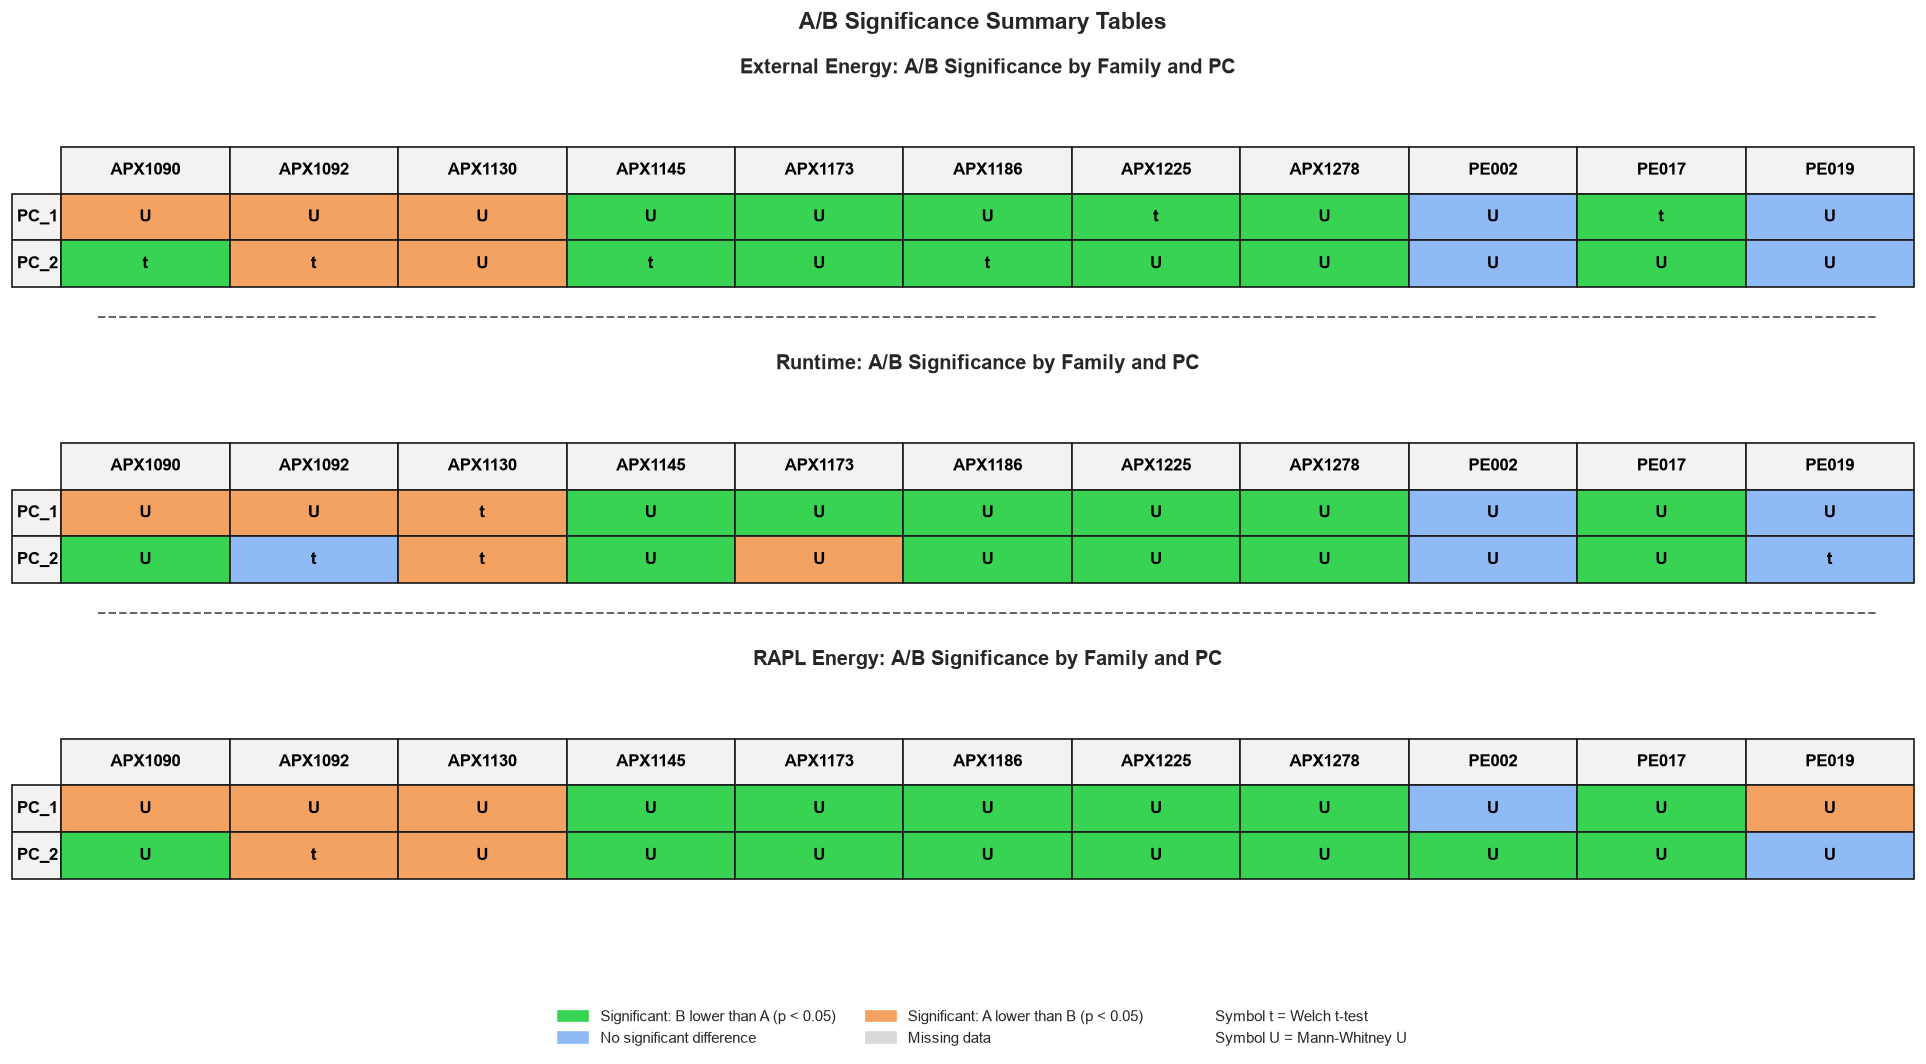

In [19]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from pathlib import Path

# Summary image tables: per-family A/B significance per PC.
# Color rules:
# - Green: significant (p < 0.05) and B lower than A (A_mean > B_mean)
# - Light blue: not significant
# - Orange: significant (p < 0.05) and A lower than B (A_mean < B_mean)
# Cell symbols indicate the test used.

if "stats_df" not in globals() or stats_df.empty:
    print("stats_df is not available. Run the A/B statistics cell first.")
else:
    save_dir = Path("plots")
    save_dir.mkdir(parents=True, exist_ok=True)

    color_green = "#39d353"
    color_blue = "#8fbaf5"
    color_orange = "#f4a261"
    color_missing = "#d9d9d9"

    symbol_map = {
        "welch_ttest": "t",
        "mannwhitney_u": "U",
    }

    metric_specs = [
        ("energy_external_j", "External Energy: A/B Significance by Family and PC"),
        ("runtime_sec", "Runtime: A/B Significance by Family and PC"),
        ("energy_rapl_j", "RAPL Energy: A/B Significance by Family and PC"),
    ]

    pcs_order = [pc for pc in ["PC_1", "PC_2"] if pc in set(stats_df["pc"])]

    def build_matrix_for_metric(metric_label: str):
        sdf = stats_df[stats_df["metric"] == metric_label].copy()
        if sdf.empty:
            return None, None, None

        families = sorted(sdf["query_family"].dropna().unique())

        text_matrix = []
        color_matrix = []

        for pc in pcs_order:
            row_text = []
            row_color = []

            for fam in families:
                row = sdf[(sdf["pc"] == pc) & (sdf["query_family"] == fam)]

                if row.empty:
                    row_text.append("-")
                    row_color.append(color_missing)
                    continue

                r = row.iloc[0]
                p = float(r["p_value"]) if pd.notna(r["p_value"]) else np.nan
                a_mean = float(r["A_mean"]) if pd.notna(r["A_mean"]) else np.nan
                b_mean = float(r["B_mean"]) if pd.notna(r["B_mean"]) else np.nan
                test_used = str(r["test_used"]) if pd.notna(r["test_used"]) else ""

                symbol = symbol_map.get(test_used, "?")
                row_text.append(symbol)

                if np.isnan(p) or np.isnan(a_mean) or np.isnan(b_mean):
                    row_color.append(color_missing)
                elif p < 0.05:
                    if b_mean < a_mean:
                        row_color.append(color_green)
                    elif a_mean < b_mean:
                        row_color.append(color_orange)
                    else:
                        row_color.append(color_blue)
                else:
                    row_color.append(color_blue)

            text_matrix.append(row_text)
            color_matrix.append(row_color)

        return families, text_matrix, color_matrix

    metric_payloads = []
    for metric_label, title in metric_specs:
        families, text_matrix, color_matrix = build_matrix_for_metric(metric_label)
        metric_payloads.append((metric_label, title, families, text_matrix, color_matrix))

    valid_payloads = [p for p in metric_payloads if p[2] is not None]
    if not valid_payloads:
        print("No rows found in stats_df for the requested significance metrics.")
    else:
        fig, axes = plt.subplots(
            len(metric_specs),
            1,
            figsize=(16, 9),
            gridspec_kw={"hspace": 0.18},
        )

        if len(metric_specs) == 1:
            axes = [axes]

        for idx, (ax, payload) in enumerate(zip(axes, metric_payloads)):
            metric_label, title, families, text_matrix, color_matrix = payload
            ax.axis("off")

            if families is None:
                ax.text(0.5, 0.5, f"No rows found for metric '{metric_label}'.", ha="center", va="center", transform=ax.transAxes)
            else:
                table = ax.table(
                    cellText=text_matrix,
                    cellLoc="center",
                    rowLabels=pcs_order,
                    colLabels=families,
                    bbox=[0.0, 0.16, 1.0, 0.56],
                )

                table.auto_set_font_size(False)
                table.set_fontsize(10)

                # Header style.
                for c in range(len(families)):
                    table[(0, c)].set_facecolor("#f2f2f2")
                    table[(0, c)].set_text_props(weight="bold", color="black")

                # Row label style.
                for r in range(1, len(pcs_order) + 1):
                    table[(r, -1)].set_facecolor("#f2f2f2")
                    table[(r, -1)].set_text_props(weight="bold", color="black")

                # Data cells.
                for r in range(len(pcs_order)):
                    for c in range(len(families)):
                        table[(r + 1, c)].set_facecolor(color_matrix[r][c])
                        table[(r + 1, c)].set_text_props(color="black", weight="bold")

            ax.set_title(title, fontsize=12, weight="bold", pad=2)

            # Visual divider between subtables.
            if idx < len(metric_specs) - 1:
                ax.plot([0.02, 0.98], [0.04, 0.04], transform=ax.transAxes, color="#666", linewidth=1.2, linestyle="--")

        legend_handles = [
            mpatches.Patch(color=color_green, label="Significant: B lower than A (p < 0.05)"),
            mpatches.Patch(color=color_blue, label="No significant difference"),
            mpatches.Patch(color=color_orange, label="Significant: A lower than B (p < 0.05)"),
            mpatches.Patch(color=color_missing, label="Missing data"),
            Line2D([0], [0], color="none", label="Symbol t = Welch t-test"),
            Line2D([0], [0], color="none", label="Symbol U = Mann-Whitney U"),
        ]

        fig.legend(
            handles=legend_handles,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            frameon=False,
            ncol=3,
            fontsize=9,
        )

        fig.suptitle("A/B Significance Summary Tables", fontsize=14, weight="bold", y=0.98)
        fig.subplots_adjust(left=0.02, right=0.985, top=0.92, bottom=0.14, hspace=0.24)

        out_path = save_dir / "ab_significance_tables_combined.svg"
        fig.savefig(out_path, format="svg", bbox_inches="tight")
        print(f"Saved: {out_path}")
        plt.show()

Saved: plots\ab_mean_pct_diff_energy.svg


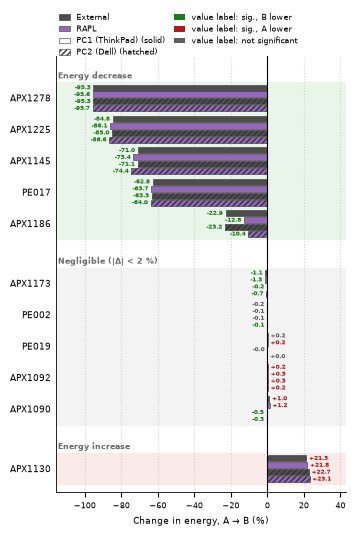

In [20]:
from pathlib import Path
import matplotlib.patches as mpatches

# =====================================================================================
# A/B mean % change in energy per guideline: RAPL vs External, BOTH PCs in ONE vertical plot.
#   change = 100 * (B_mean - A_mean) / A_mean          (negative = B uses less energy)
# Layout follows the double-column IEEEtran paper (see main.tex): single column = 3.5 in wide.
# Guidelines run down the y-axis (grouped as in the forest plot); each guideline has four bars:
#   PC_1 External, PC_1 RAPL (solid)  |  PC_2 External, PC_2 RAPL (hatched).
# Bar colour = measurement source. Value-label colour = significance. Drawn by figure_style.mean_pct_bars().
# =====================================================================================

# ---- shared settings (also used by the forest plot cell) ----
FIG_COL_W = 3.5      # IEEEtran single-column width, inches
FIG_FULL_W = 7.16    # IEEEtran full (figure*) width, inches
PC_DISPLAY = {"PC_1": "ThinkPad (PC_1)", "PC_2": "Dell (PC_2)"}

GROUP_LARGE_REDUCTION_PCT = -20.0   # mean energy change below this      -> "Large reduction"
GROUP_NEGLIGIBLE_PCT = 2.0          # mean energy change above this      -> "Energy increase"; in between -> "Negligible"
GROUP_NAMES = {0: "Energy decrease", 1: f"Negligible (|Δ| < {GROUP_NEGLIGIBLE_PCT:g} %)", 2: "Energy increase"}
GROUP_BAND_COLORS = {0: "#e8f5e8", 1: "#f3f3f3", 2: "#fbeaea"}   # same tints as figure_style.py
NEGLIGIBLE_GROUP = 1


def guideline_groups(sdf: pd.DataFrame, metric: str = "energy_external_j"):
    """Order guidelines by group, then by mean A->B energy change across PCs. Returns (order, {family: group})."""
    d = sdf[sdf["metric"] == metric].copy()
    d["chg"] = np.where(d["A_mean"] != 0, 100.0 * (d["B_mean"] - d["A_mean"]) / d["A_mean"], np.nan)
    mean_chg = d.groupby("query_family")["chg"].mean().dropna()
    grp = {f: (0 if v < GROUP_LARGE_REDUCTION_PCT else (2 if v > GROUP_NEGLIGIBLE_PCT else 1)) for f, v in mean_chg.items()}
    order = sorted(mean_chg.index, key=lambda f: (grp[f], mean_chg[f]))
    return order, grp


def grouped_ypos(order, grp, gap: float = 0.9):
    ypos, y, last = {}, 0.0, None
    for f in order:
        if last is not None and grp[f] != last:
            y += gap
        ypos[f] = y
        y += 1.0
        last = grp[f]
    return ypos


def draw_group_bands(ax, order, ypos, grp, x_left, fontsize=5.5):
    for g in (0, 1, 2):
        ys = [ypos[f] for f in order if grp[f] == g]
        if ys:
            ax.axhspan(min(ys) - 0.5, max(ys) + 0.5, color=GROUP_BAND_COLORS[g], zorder=0)
            ax.text(x_left + 0.01 * abs(x_left), min(ys) - 0.56, GROUP_NAMES[g], fontsize=fontsize,
                    fontweight="bold", color="#6b6b6b", va="bottom")


if "stats_df" not in globals() or stats_df.empty:
    print("stats_df is not available. Run the A/B statistics cell first.")
else:
    import importlib
    import figure_style as fs
    importlib.reload(fs)
    fs.mean_pct_bars(stats_df, "ab_mean_pct_diff_energy")


Saved: plots\ab_savings_scatter_external_pct.svg


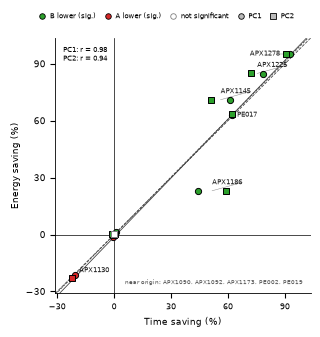

Saved: plots\ab_savings_scatter_external_abs.svg


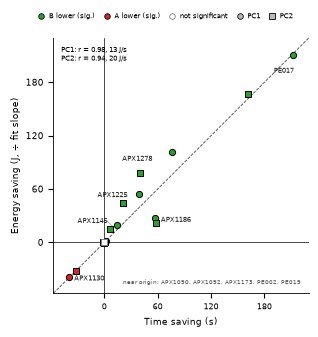

Saved: plots\ab_savings_scatter_external_abs_raw.svg


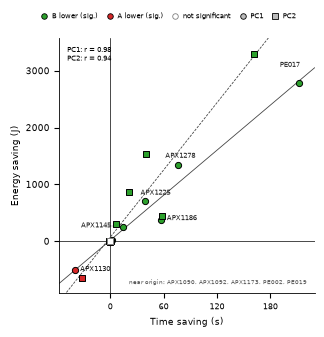

Saved: plots\ab_savings_scatter_rapl_pct.svg


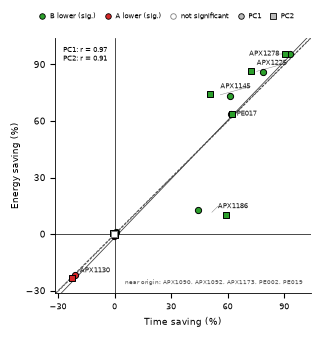

Saved: plots\ab_savings_scatter_rapl_abs.svg


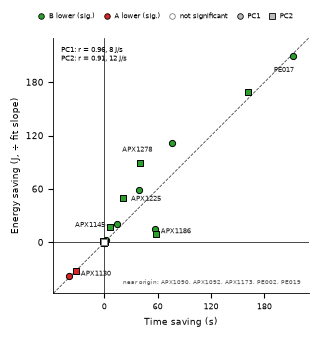

Saved: plots\ab_savings_scatter_rapl_abs_raw.svg


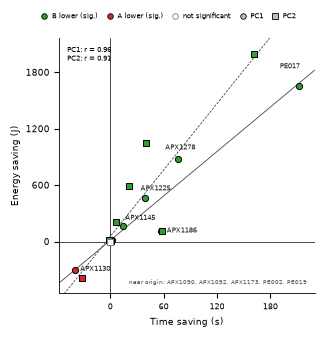

In [21]:
# A/B savings scatter plots (paper style, one column): time saving vs energy saving, one panel per PC.
# Colours/markers follow figure_style (green/red/hollow = energy-test outcome, circle = PC1, square = PC2).
import importlib
import figure_style as fs
importlib.reload(fs)

for source in ("External", "RAPL"):
    for kind in ("pct", "abs_norm", "abs_raw"):
        scatter_tables = fs.savings_scatter(stats_df, source=source, kind=kind)


Saved: plots\ab_forest_energy_external_pct.svg


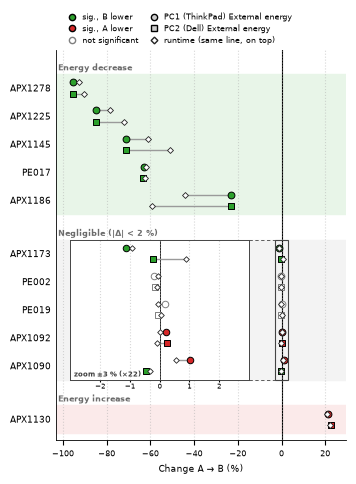

Saved: plots\ab_forest_energy_rapl_pct.svg


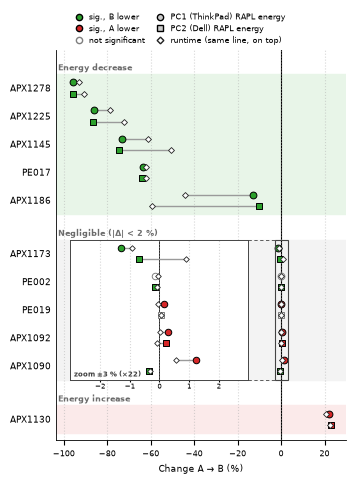

In [22]:
# Forest plot: percent energy change per guideline, significance as marker fill, runtime as a second marker.
# Single column of the IEEEtran paper; drawn by figure_style.forest(). Row order/groups follow the EXTERNAL energy change.
import importlib
import figure_style as fs   # shared palette + paper-figure functions (analysis/figure_style.py)
importlib.reload(fs)

order, grp = fs.guideline_groups(stats_df)
fs.write_group_file(order, grp)   # plots/guideline_groups.json, shared with the planning-time notebook
fs.forest(stats_df, "energy_external_j", "External", "ab_forest_energy_external_pct")
fs.forest(stats_df, "energy_rapl_j", "RAPL", "ab_forest_energy_rapl_pct")


In [23]:
# Save core presentation figures to plots/ (reproducible exports)
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

save_dir = Path("plots")
save_dir.mkdir(parents=True, exist_ok=True)

def _save_avg_power_plot():
    if "avg_long" not in globals() or avg_long is None or avg_long.empty:
        print("Skip avg power export: avg_long not available.")
        return
    g = sns.catplot(
        data=avg_long,
        x="query_family",
        y="avg_power_w",
        hue="variant",
        row="pc",
        col="source",
        row_order=["PC_1", "PC_2"],
        col_order=["RAPL", "External"],
        order=query_order,
        kind="box",
        height=3.7,
        aspect=1.7,
        sharey="row",
    )
    g.set_axis_labels("Query Family", "Average Power (W)")
    g.set_titles(row_template="{row_name}", col_template="{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    plt.tight_layout()
    out_path = save_dir / "ab_avg_power_boxplot.svg"
    g.figure.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.close(g.figure)

def _save_energy_plot():
    if "energy_long" not in globals() or energy_long is None or energy_long.empty:
        print("Skip energy export: energy_long not available.")
        return
    g = sns.catplot(
        data=energy_long,
        x="query_family",
        y="energy_j",
        hue="variant",
        row="pc",
        col="source",
        row_order=["PC_1", "PC_2"],
        col_order=["RAPL", "External"],
        order=query_order,
        kind="box",
        height=3.7,
        aspect=1.7,
        sharey="row",
    )
    g.set_axis_labels("Query Family", "Total Energy (J)")
    g.set_titles(row_template="{row_name}", col_template="{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    # Keep legend outside the plotting area so it does not block any boxplots.
    sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, title="variant")
    g.figure.subplots_adjust(right=0.86)
    plt.tight_layout()
    out_path = save_dir / "ab_total_energy_boxplot.svg"
    g.figure.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.close(g.figure)

def _save_runtime_plot():
    if "runtime_df" not in globals() or runtime_df is None or runtime_df.empty:
        print("Skip runtime export: runtime_df not available.")
        return
    g = sns.catplot(
        data=runtime_df,
        x="query_family",
        y="total_elapsed_sec",
        hue="variant",
        row="pc",
        row_order=["PC_1", "PC_2"],
        order=query_order,
        kind="box",
        height=4.2,
        aspect=3.6,
        sharey=False,
    )
    g.set_axis_labels("Query Family", "Run Time (s)")
    g.set_titles(row_template="{row_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    add_query_dividers(g, len(query_order))
    plt.tight_layout()
    out_path = save_dir / "ab_runtime_boxplot.svg"
    g.figure.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.close(g.figure)

def _save_sig_counts_plot():
    local_sig_counts = None
    if "sig_counts" in globals() and isinstance(sig_counts, pd.DataFrame) and not sig_counts.empty:
        local_sig_counts = sig_counts.copy()
    elif "stats_df" in globals() and isinstance(stats_df, pd.DataFrame) and not stats_df.empty:
        local_sig_counts = (
            stats_df.groupby(["pc", "metric"], as_index=False)["significant_0_05"]
            .sum()
            .rename(columns={"significant_0_05": "n_significant_families"})
        )
    if local_sig_counts is None or local_sig_counts.empty:
        print("Skip significance-count export: no stats available.")
        return

    plt.figure(figsize=(12, 5))
    sns.barplot(
        data=local_sig_counts,
        x="metric",
        y="n_significant_families",
        hue="pc",
        palette="Set2",
    )
    plt.xticks(rotation=35, ha="right")
    plt.xlabel("Metric")
    plt.ylabel("Significant Families (p < 0.05)")
    plt.title("Significant A/B Families by PC and Metric")
    plt.tight_layout()
    out_path = save_dir / "ab_significant_counts_by_pc_metric.svg"
    plt.savefig(out_path, format="svg", bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.close()

_save_avg_power_plot()
_save_energy_plot()
_save_runtime_plot()
_save_sig_counts_plot()

Saved: plots\ab_avg_power_boxplot.svg


Saved: plots\ab_total_energy_boxplot.svg


Saved: plots\ab_runtime_boxplot.svg
Saved: plots\ab_significant_counts_by_pc_metric.svg


In [24]:
# Family-level A/B delta tests (QUERYA - QUERYB) for cross-source/PC comparisons.
from scipy.stats import spearmanr, wilcoxon

def _family_ab_delta_table(df: pd.DataFrame, value_col: str) -> pd.DataFrame:
    if df is None or value_col not in df.columns:
        return pd.DataFrame(columns=["query_family", "delta_A_minus_B"])
    subset = df[df["variant"].isin(["QUERYA", "QUERYB"]) & df["query_family"].notna()].copy()
    if subset.empty:
        return pd.DataFrame(columns=["query_family", "delta_A_minus_B"])
    fam = subset.groupby(["query_family", "variant"])[value_col].median().unstack()
    if not {"QUERYA", "QUERYB"}.issubset(fam.columns):
        return pd.DataFrame(columns=["query_family", "delta_A_minus_B"])
    fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
    fam["delta_A_minus_B"] = fam["QUERYA"] - fam["QUERYB"]
    return fam[["delta_A_minus_B"]].reset_index()

def _sign_labels(values: np.ndarray, eps: float = 1e-12):
    labels = []
    for v in values:
        if v > eps:
            labels.append("pos")
        elif v < -eps:
            labels.append("neg")
        else:
            labels.append("zero")
    return labels

def _cohens_kappa(labels_a, labels_b) -> float:
    if len(labels_a) == 0 or len(labels_a) != len(labels_b):
        return np.nan
    df = pd.DataFrame({"a": labels_a, "b": labels_b})
    categories = ["pos", "neg", "zero"]
    table = pd.crosstab(df["a"], df["b"], dropna=False).reindex(index=categories, columns=categories, fill_value=0)
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    p_o = np.trace(table.to_numpy()) / n
    row_marg = table.sum(axis=1).to_numpy() / n
    col_marg = table.sum(axis=0).to_numpy() / n
    p_e = float(np.dot(row_marg, col_marg))
    if np.isclose(1.0 - p_e, 0.0):
        return np.nan
    return (p_o - p_e) / (1.0 - p_e)

def _cohens_d_paired(x: np.ndarray, y: np.ndarray) -> float:
    diff = x - y
    std = np.std(diff, ddof=1)
    if not np.isfinite(std) or std == 0:
        return np.nan
    return float(np.mean(diff) / std)

def _empty_stats(note: str = "no_pairs") -> dict:
    return {
        "n": 0,
        "spearman_rho": np.nan,
        "spearman_p": np.nan,
        "cohens_d": np.nan,
        "cohens_kappa": np.nan,
        "wilcoxon_stat": np.nan,
        "wilcoxon_p": np.nan,
        "note": note,
    }

def _paired_stats_table(x: np.ndarray, y: np.ndarray) -> dict:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    n = len(x)
    if n < 2:
        return _empty_stats("insufficient_pairs") if n > 0 else _empty_stats("no_pairs")

    rho, p = spearmanr(x, y)
    diff = x - y

    labels_x = _sign_labels(x)
    labels_y = _sign_labels(y)
    kappa = _cohens_kappa(labels_x, labels_y)
    cohens_d = _cohens_d_paired(x, y)

    if np.allclose(diff, 0):
        return {
            "n": int(n),
            "spearman_rho": float(rho) if np.isfinite(rho) else np.nan,
            "spearman_p": float(p) if np.isfinite(p) else np.nan,
            "cohens_d": 0.0,
            "cohens_kappa": kappa,
            "wilcoxon_stat": np.nan,
            "wilcoxon_p": np.nan,
            "note": "all_differences_zero",
        }

    try:
        w_res = wilcoxon(x, y, alternative="two-sided")
        w_stat = float(w_res.statistic)
        w_p = float(w_res.pvalue)
        note = "ok"
    except ValueError:
        w_stat = np.nan
        w_p = np.nan
        note = "wilcoxon_error"

    return {
        "n": int(n),
        "spearman_rho": float(rho) if np.isfinite(rho) else np.nan,
        "spearman_p": float(p) if np.isfinite(p) else np.nan,
        "cohens_d": cohens_d,
        "cohens_kappa": kappa,
        "wilcoxon_stat": w_stat,
        "wilcoxon_p": w_p,
        "note": note,
    }

def _stats_row(label: str, stats: dict) -> dict:
    return {
        "comparison": label,
        "n_query_families": stats["n"],
        "spearman_rho": stats["spearman_rho"],
        "spearman_p": stats["spearman_p"],
        "cohens_d": stats["cohens_d"],
        "cohens_kappa": stats["cohens_kappa"],
        "wilcoxon_stat": stats["wilcoxon_stat"],
        "wilcoxon_p": stats["wilcoxon_p"],
        "note": stats["note"],
    }

def _join_deltas(left: pd.DataFrame, right: pd.DataFrame, left_label: str, right_label: str):
    joined = left.merge(right, on="query_family", suffixes=(f"_{left_label}", f"_{right_label}"))
    x_col = f"delta_A_minus_B_{left_label}"
    y_col = f"delta_A_minus_B_{right_label}"
    return joined, x_col, y_col

# Table 1: within each PC, compare RAPL vs External deltas (family-level A/B).
rows = []
for pc_name, payload in per_pc.items():
    mdf = payload.get("merged")
    rapl = _family_ab_delta_table(mdf, "rapl_package_j")
    ext = _family_ab_delta_table(mdf, "external_energy_j")
    joined, x_col, y_col = _join_deltas(rapl, ext, "rapl", "external")
    stats = _paired_stats_table(joined[x_col], joined[y_col]) if not joined.empty else _empty_stats()
    rows.append({"pc": pc_name, **_stats_row("rapl_vs_external", stats)})

table1 = pd.DataFrame(rows)
print("1) Within-PC: RAPL vs External (family-level A/B deltas)")
if table1.empty:
    print("No data available for within-PC RAPL vs External tests.")
else:
    display(table1.sort_values(["pc"]))

# Table 2: across PCs, compare deltas for each measurement independently.
pc_order = [pc for pc in ["PC_1", "PC_2"] if pc in per_pc]
table2_rows = []
metric_specs = [
    ("rapl_package_j", "rapl_energy"),
    ("external_energy_j", "external_energy"),
    ("total_elapsed_sec", "runtime"),
]
if len(pc_order) < 2:
    print("2) Across-PC: not enough PCs available for comparison.")
else:
    for col, label in metric_specs:
        left = _family_ab_delta_table(per_pc[pc_order[0]]["merged"], col)
        right = _family_ab_delta_table(per_pc[pc_order[1]]["merged"], col)
        joined, x_col, y_col = _join_deltas(left, right, pc_order[0], pc_order[1])
        stats = _paired_stats_table(joined[x_col], joined[y_col]) if not joined.empty else _empty_stats()
        row = {
            "metric": label,
            "pc_left": pc_order[0],
            "pc_right": pc_order[1],
        }
        row.update(_stats_row("pc_vs_pc", stats))
        table2_rows.append(row)

    table2 = pd.DataFrame(table2_rows)
    print("2) Across-PC: compare deltas for RAPL, External, and Runtime")
    if table2.empty:
        print("No data available for across-PC comparisons.")
    else:
        display(table2)

# Table 3: cross-PC, cross-source comparisons.
table3_rows = []
if {"PC_1", "PC_2"}.issubset(per_pc.keys()):
    pc1_rapl = _family_ab_delta_table(per_pc["PC_1"]["merged"], "rapl_package_j")
    pc2_ext = _family_ab_delta_table(per_pc["PC_2"]["merged"], "external_energy_j")
    joined, x_col, y_col = _join_deltas(pc1_rapl, pc2_ext, "pc1_rapl", "pc2_external")
    stats = _paired_stats_table(joined[x_col], joined[y_col]) if not joined.empty else _empty_stats()
    table3_rows.append(_stats_row("PC_1_RAPL_vs_PC_2_External", stats))

    pc2_rapl = _family_ab_delta_table(per_pc["PC_2"]["merged"], "rapl_package_j")
    pc1_ext = _family_ab_delta_table(per_pc["PC_1"]["merged"], "external_energy_j")
    joined, x_col, y_col = _join_deltas(pc2_rapl, pc1_ext, "pc2_rapl", "pc1_external")
    stats = _paired_stats_table(joined[x_col], joined[y_col]) if not joined.empty else _empty_stats()
    table3_rows.append(_stats_row("PC_2_RAPL_vs_PC_1_External", stats))

table3 = pd.DataFrame(table3_rows)
print("3) Cross-PC: PC1 RAPL vs PC2 External, and PC2 RAPL vs PC1 External")
if table3.empty:
    print("No data available for cross-PC cross-source comparisons.")
else:
    display(table3)

1) Within-PC: RAPL vs External (family-level A/B deltas)


,pc,comparison,n_query_families,spearman_rho,spearman_p,cohens_d,cohens_kappa,wilcoxon_stat,wilcoxon_p,note
0,PC_1,rapl_vs_external,11,0.990909,3.762572e-09,-0.497368,1.000000,17.0,0.174805,ok
1,PC_2,rapl_vs_external,11,0.981818,8.403066e-08,-0.484404,0.744186,12.0,0.067383,ok


2) Across-PC: compare deltas for RAPL, External, and Runtime


,metric,pc_left,pc_right,comparison,n_query_families,spearman_rho,spearman_p,cohens_d,cohens_kappa,wilcoxon_stat,wilcoxon_p,note
0,rapl_energy,PC_1,PC_2,pc_vs_pc,11,0.945455,0.000011,-0.473808,0.620690,20.0,0.278320,ok
1,external_energy,PC_1,PC_2,pc_vs_pc,11,0.936364,0.000022,-0.458907,0.421053,13.0,0.083008,ok
2,runtime,PC_1,PC_2,pc_vs_pc,11,0.818182,0.002083,0.528887,0.241379,21.0,0.320312,ok


3) Cross-PC: PC1 RAPL vs PC2 External, and PC2 RAPL vs PC1 External


,comparison,n_query_families,spearman_rho,spearman_p,cohens_d,cohens_kappa,wilcoxon_stat,wilcoxon_p,note
0,PC_1_RAPL_vs_PC_2_External,11,0.927273,0.000040,-0.486081,0.421053,14.0,0.101562,ok
1,PC_2_RAPL_vs_PC_1_External,11,0.936364,0.000022,-0.495741,0.620690,17.0,0.174805,ok


Saved: plots\energy_rapl_ordered_by_external_column.svg


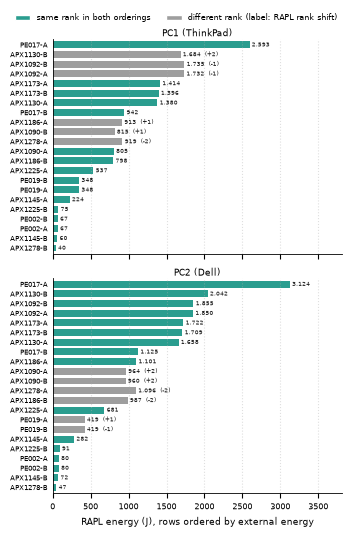

In [25]:
# Rank order: bars = RAPL energy, rows ordered by external energy; teal = same rank, grey = different rank.
# Paper version: horizontal bars, both PCs stacked, one column. Other layouts: layout='side' | 'vertical'.
import importlib
import figure_style as fs   # shared palette + paper-figure functions (analysis/figure_style.py)
importlib.reload(fs)

rank_tables = fs.rank_bars(analysis_df, layout="column")


In [26]:
# LaTeX tables for mean (SD) per query family, split by PC and metric.
preferred_query_order = [
    "APX1090",
    "APX1092",
    "APX1130",
    "APX1145",
    "APX1173",
    "APX1186",
    "APX1225",
    "APX1278",
    "PE002",
    "PE017",
    "PE019",
]

def _format_mean_sd(values: pd.Series, decimals: int = 2) -> str:
    series = pd.to_numeric(values, errors="coerce").dropna()
    if series.empty:
        return ""
    mean = float(series.mean())
    sd = float(series.std(ddof=1)) if len(series) > 1 else 0.0
    if not np.isfinite(sd):
        sd = 0.0
    return f"{mean:.{decimals}f}({sd:.{decimals}f})"

def _ordered_families(df: pd.DataFrame) -> list:
    families = [f for f in df["query_family"].dropna().unique()]
    ordered = [f for f in preferred_query_order if f in families]
    ordered += [f for f in families if f not in ordered]
    return ordered

def _latex_table_for_pc_metric(pc_name: str, value_col: str, caption: str, label: str):
    pc_df = plot_df[
        (plot_df["pc"] == pc_name)
        & (plot_df["variant"].isin(["QUERYA", "QUERYB"]))
        & plot_df["query_family"].notna()
    ].copy()
    if pc_df.empty or value_col not in pc_df.columns:
        print(f"% No data for {pc_name} {value_col}")
        return
    fam_order = _ordered_families(pc_df)
    lines = [
        "\\begin{table}[H]",
        "\\centering",
        "\\begin{tabular}{ccc} \\toprule",
        "    Query & A Mean(SD) & B Mean(SD)\\\\ \\midrule",
    ]
    for fam in fam_order:
        a_vals = pc_df[(pc_df["query_family"] == fam) & (pc_df["variant"] == "QUERYA")][value_col]
        b_vals = pc_df[(pc_df["query_family"] == fam) & (pc_df["variant"] == "QUERYB")][value_col]
        a_text = _format_mean_sd(a_vals)
        b_text = _format_mean_sd(b_vals)
        lines.append(f"    {fam} & {a_text} & {b_text} \\\\")
    lines += [
        "\\bottomrule",
        "\\end{tabular}",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        "\\end{table}",
    ]
    print("\n".join(lines))
    print("")

def _pc_label(pc_name: str) -> str:
    return pc_name.replace("PC_", "PC")

metrics = [
    ("external_energy_j", "External Mean and Standard Deviation", "external-means-sd"),
    ("rapl_package_j", "RAPL Mean and Standard Deviation", "rapl-means-sd"),
    ("total_elapsed_sec", "Runtime Mean and Standard Deviation", "runtime-means-sd"),
]

for pc_name in ["PC_1", "PC_2"]:
    pc_label = _pc_label(pc_name).lower()
    pc_caption = _pc_label(pc_name)
    for col, caption_prefix, label_prefix in metrics:
        caption = f"{caption_prefix} ({pc_caption})"
        label = f"table:{label_prefix}-{pc_label}"
        _latex_table_for_pc_metric(pc_name, col, caption, label)

\begin{table}[H]
\centering
\begin{tabular}{ccc} \toprule
    Query & A Mean(SD) & B Mean(SD)\\ \midrule
    APX1090 & 1410.22(5.08) & 1424.86(3.45) \\
    APX1092 & 2732.80(11.07) & 2738.78(9.79) \\
    APX1130 & 2396.56(12.84) & 2907.00(6.62) \\
    APX1145 & 356.74(4.66) & 103.44(1.94) \\
    APX1173 & 2459.27(5.82) & 2431.79(7.07) \\
    APX1186 & 1609.13(5.85) & 1240.21(5.99) \\
    APX1225 & 843.88(6.35) & 128.54(1.96) \\
    APX1278 & 1411.23(5.73) & 66.89(2.59) \\
    PE002 & 115.56(3.01) & 115.33(1.94) \\
    PE017 & 4417.40(7.13) & 1641.88(3.80) \\
    PE019 & 612.88(4.46) & 613.89(5.73) \\
\bottomrule
\end{tabular}
\caption{External Mean and Standard Deviation (PC1)}
\label{table:external-means-sd-pc1}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{ccc} \toprule
    Query & A Mean(SD) & B Mean(SD)\\ \midrule
    APX1090 & 804.95(2.60) & 814.89(1.08) \\
    APX1092 & 1730.11(8.18) & 1735.11(1.12) \\
    APX1130 & 1382.31(9.49) & 1684.32(1.69) \\
    APX1145 & 224.33

\begin{table}[H]
\centering
\begin{tabular}{ccc} \toprule
    Query & A Mean(SD) & B Mean(SD)\\ \midrule
    APX1090 & 1648.06(8.00) & 1640.44(5.92) \\
    APX1092 & 2938.95(15.94) & 2946.63(12.13) \\
    APX1130 & 2814.63(11.92) & 3452.85(7.25) \\
    APX1145 & 417.92(6.98) & 120.87(4.56) \\
    APX1173 & 2913.66(5.17) & 2907.23(9.00) \\
    APX1186 & 1890.43(5.70) & 1452.03(19.06) \\
    APX1225 & 1014.55(8.61) & 151.92(3.92) \\
    APX1278 & 1607.38(16.54) & 76.02(4.11) \\
    PE002 & 135.41(4.56) & 135.21(2.31) \\
    PE017 & 5212.15(11.12) & 1913.77(8.09) \\
    PE019 & 729.12(8.22) & 728.78(6.08) \\
\bottomrule
\end{tabular}
\caption{External Mean and Standard Deviation (PC2)}
\label{table:external-means-sd-pc2}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{ccc} \toprule
    Query & A Mean(SD) & B Mean(SD)\\ \midrule
    APX1090 & 963.35(5.69) & 959.98(1.41) \\
    APX1092 & 1849.87(8.69) & 1854.13(8.10) \\
    APX1130 & 1660.29(6.99) & 2043.21(3.93) \\
    APX1145 & 2

In [27]:
# LaTeX tables: External + Runtime with PC1/PC2 side-by-side A/B (mean(SD)).
def _latex_ab_pc_table(value_col: str, caption: str, label: str) -> None:
    base_df = plot_df[
        (plot_df["variant"].isin(["QUERYA", "QUERYB"]))
        & plot_df["query_family"].notna()
    ].copy()
    if base_df.empty or value_col not in base_df.columns:
        print(f"% No data for {value_col}")
        return
    fam_order = _ordered_families(base_df)
    lines = [
        "\\begin{table}[H]",
        "\\centering",
        "\\begin{tabular}{ccccc} \\toprule",
        "    Query & PC1 A(SD) & PC1 B(SD) & PC2 A(SD) & PC2 B(SD)\\\\ \\midrule",
    ]
    for fam in fam_order:
        row_vals = []
        for pc_name in ["PC_1", "PC_2"]:
            a_vals = base_df[
                (base_df["query_family"] == fam)
                & (base_df["pc"] == pc_name)
                & (base_df["variant"] == "QUERYA")
            ][value_col]
            b_vals = base_df[
                (base_df["query_family"] == fam)
                & (base_df["pc"] == pc_name)
                & (base_df["variant"] == "QUERYB")
            ][value_col]
            row_vals.append(_format_mean_sd(a_vals))
            row_vals.append(_format_mean_sd(b_vals))
        lines.append(
            f"    {fam} & {row_vals[0]} & {row_vals[1]} & {row_vals[2]} & {row_vals[3]} \\\\")
    lines += [
        "\\bottomrule",
        "\\end{tabular}",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        "\\end{table}",
    ]
    print("\n".join(lines))
    print("")

# External energy table: PC1/PC2 side-by-side.
_latex_ab_pc_table(
    "external_energy_j",
    "External Mean and Standard Deviation (PC1 vs PC2)",
    "table:external-means-sd-pc1-pc2",
)

# Runtime table: PC1/PC2 side-by-side.
_latex_ab_pc_table(
    "total_elapsed_sec",
    "Runtime Mean and Standard Deviation (PC1 vs PC2)",
    "table:runtime-means-sd-pc1-pc2",
)

\begin{table}[H]
\centering
\begin{tabular}{ccccc} \toprule
    Query & PC1 A(SD) & PC1 B(SD) & PC2 A(SD) & PC2 B(SD)\\ \midrule
    APX1090 & 1410.22(5.08) & 1424.86(3.45) & 1648.06(8.00) & 1640.44(5.92) \\
    APX1092 & 2732.80(11.07) & 2738.78(9.79) & 2938.95(15.94) & 2946.63(12.13) \\
    APX1130 & 2396.56(12.84) & 2907.00(6.62) & 2814.63(11.92) & 3452.85(7.25) \\
    APX1145 & 356.74(4.66) & 103.44(1.94) & 417.92(6.98) & 120.87(4.56) \\
    APX1173 & 2459.27(5.82) & 2431.79(7.07) & 2913.66(5.17) & 2907.23(9.00) \\
    APX1186 & 1609.13(5.85) & 1240.21(5.99) & 1890.43(5.70) & 1452.03(19.06) \\
    APX1225 & 843.88(6.35) & 128.54(1.96) & 1014.55(8.61) & 151.92(3.92) \\
    APX1278 & 1411.23(5.73) & 66.89(2.59) & 1607.38(16.54) & 76.02(4.11) \\
    PE002 & 115.56(3.01) & 115.33(1.94) & 135.41(4.56) & 135.21(2.31) \\
    PE017 & 4417.40(7.13) & 1641.88(3.80) & 5212.15(11.12) & 1913.77(8.09) \\
    PE019 & 612.88(4.46) & 613.89(5.73) & 729.12(8.22) & 728.78(6.08) \\
\bottomrule
\end{ta

In [28]:
# Research questions: statistical agreement between RAPL and external measurements.
from scipy.stats import spearmanr, kendalltau, wilcoxon

def _family_ab_medians(df: pd.DataFrame, value_col: str) -> pd.DataFrame:
    if value_col not in df.columns:
        return pd.DataFrame()
    subset = df[
        df["variant"].isin(["QUERYA", "QUERYB"])
        & df["query_family"].notna()
        & df[value_col].notna()
    ].copy()
    if subset.empty:
        return pd.DataFrame()
    fam = subset.groupby(["query_family", "variant"])[value_col].median().unstack()
    if not {"QUERYA", "QUERYB"}.issubset(fam.columns):
        return pd.DataFrame()
    fam = fam.dropna(subset=["QUERYA", "QUERYB"]).copy()
    fam["delta_A_minus_B"] = fam["QUERYA"] - fam["QUERYB"]
    fam["pct_A_minus_B"] = np.where(
        fam["QUERYA"] != 0,
        100.0 * (fam["QUERYA"] - fam["QUERYB"]) / fam["QUERYA"],
        np.nan,
    )
    return fam

def _sign_labels(values: np.ndarray, eps: float = 1e-12):
    labels = []
    for v in values:
        if v > eps:
            labels.append("pos")
        elif v < -eps:
            labels.append("neg")
        else:
            labels.append("zero")
    return labels

def _cohens_kappa(labels_a, labels_b) -> float:
    if len(labels_a) == 0 or len(labels_a) != len(labels_b):
        return np.nan
    df = pd.DataFrame({"a": labels_a, "b": labels_b})
    categories = ["pos", "neg", "zero"]
    table = pd.crosstab(df["a"], df["b"], dropna=False).reindex(index=categories, columns=categories, fill_value=0)
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    p_o = np.trace(table.to_numpy()) / n
    row_marg = table.sum(axis=1).to_numpy() / n
    col_marg = table.sum(axis=0).to_numpy() / n
    p_e = float(np.dot(row_marg, col_marg))
    if np.isclose(1.0 - p_e, 0.0):
        return np.nan
    return (p_o - p_e) / (1.0 - p_e)

def _wilcoxon_safe(x: np.ndarray, y: np.ndarray):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan, np.nan, "insufficient_pairs"
    if np.allclose(x, y):
        return np.nan, np.nan, "all_equal"
    try:
        res = wilcoxon(x, y, alternative="two-sided")
        return float(res.statistic), float(res.pvalue), "ok"
    except ValueError:
        return np.nan, np.nan, "wilcoxon_error"

def _ccc(x: np.ndarray, y: np.ndarray) -> float:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan
    mean_x = float(np.mean(x))
    mean_y = float(np.mean(y))
    var_x = float(np.var(x, ddof=1))
    var_y = float(np.var(y, ddof=1))
    if not np.isfinite(var_x) or not np.isfinite(var_y):
        return np.nan
    cov = float(np.cov(x, y, ddof=1)[0, 1])
    denom = var_x + var_y + (mean_x - mean_y) ** 2
    if denom == 0 or not np.isfinite(denom):
        return np.nan
    return 2.0 * cov / denom

def _latex_escape(text: str) -> str:
    if text is None:
        return ""
    out = str(text)
    out = out.replace("\\", "\\\\")
    out = out.replace("_", "\\_")
    out = out.replace("%", "\\%")
    out = out.replace("&", "\\&")
    out = out.replace("#", "\\#")
    return out

def _format_cell(value, decimals: int = 3) -> str:
    if value is None:
        return ""
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    try:
        v = float(value)
        if not np.isfinite(v):
            return ""
        return f"{v:.{decimals}f}"
    except (TypeError, ValueError):
        return _latex_escape(value)

def _latex_table_from_df(df: pd.DataFrame, caption: str, label: str, col_order: list, col_labels: list, decimals: int = 3):
    if df.empty:
        print(f"% No data for {label}")
        return
    n_cols = len(col_order)
    align = "c" * n_cols
    header_cells = [_latex_escape(lbl) for lbl in col_labels]
    lines = [
        "\\begin{table}[H]",
        "\\centering",
        f"\\begin{{tabular}}{{{align}}} \\toprule",
        "    " + " & ".join(header_cells) + "\\\\ \\midrule",
    ]
    for _, row in df.iterrows():
        cells = [_format_cell(row[col], decimals=decimals) for col in col_order]
        lines.append("    " + " & ".join(cells) + " \\\\")
    lines += [
        "\\bottomrule",
        "\\end{tabular}",
        f"\\caption{{{_latex_escape(caption)}}}",
        f"\\label{{{_latex_escape(label)}}}",
        "\\end{table}",
    ]
    print("\n".join(lines))
    print("")

def _print_rq_tables_by_pc(df: pd.DataFrame, caption_prefix: str, label_prefix: str, col_order: list, col_labels: list, decimals: int = 3):
    for pc_name in pcs_order:
        subset = df[df["pc"] == pc_name].copy() if "pc" in df.columns else df.copy()
        if subset.empty:
            print(f"% No data for {label_prefix} {pc_name}")
            continue
        subset = subset[col_order]
        pc_label = pc_name.replace("PC_", "pc")
        pc_caption = pc_name.replace("PC_", "PC")
        caption = f"{caption_prefix} ({pc_caption})"
        label = f"table:{label_prefix}-{pc_label}"
        _latex_table_from_df(subset, caption, label, col_order, col_labels, decimals=decimals)

def _order_query_families(df: pd.DataFrame) -> pd.DataFrame:
    if "query_family" not in df.columns:
        return df
    if "preferred_query_order" in globals():
        families = df["query_family"].tolist()
        order = [f for f in preferred_query_order if f in families]
        order += [f for f in families if f not in order]
        return df.set_index("query_family").loc[order].reset_index()
    return df.sort_values("query_family").reset_index(drop=True)

pcs_order = [pc for pc in ["PC_1", "PC_2"] if pc in set(plot_df["pc"])] if "plot_df" in globals() else []
if not pcs_order:
    print("plot_df is not available. Run the data-loading cells first.")
else:
    # RQ1: Direction agreement for A vs B energy differences.
    rq1_rows = []
    for pc_name in pcs_order:
        pc_df = plot_df[plot_df["pc"] == pc_name].copy()
        ext = _family_ab_medians(pc_df, "external_energy_j")
        rapl = _family_ab_medians(pc_df, "rapl_package_j")
        joined = ext[["delta_A_minus_B"]].join(rapl[["delta_A_minus_B"]], lsuffix="_ext", rsuffix="_rapl", how="inner")
        if joined.empty:
            rq1_rows.append({
                "pc": pc_name,
                "n_families": 0,
                "agreement_rate": np.nan,
                "cohens_kappa": np.nan,
                "note": "no_overlap",
            })
            continue
        sign_ext = _sign_labels(joined["delta_A_minus_B_ext"].to_numpy())
        sign_rapl = _sign_labels(joined["delta_A_minus_B_rapl"].to_numpy())
        agree = np.mean(np.array(sign_ext) == np.array(sign_rapl)) if len(sign_ext) else np.nan
        kappa = _cohens_kappa(sign_ext, sign_rapl)
        rq1_rows.append({
            "pc": pc_name,
            "n_families": int(len(joined)),
            "agreement_rate": float(agree) if np.isfinite(agree) else np.nan,
            "cohens_kappa": kappa,
            "note": "ok",
        })

    rq1_df = pd.DataFrame(rq1_rows)
    print("RQ1: Direction agreement between RAPL and external A/B energy differences")
    display(rq1_df)
    _print_rq_tables_by_pc(
        rq1_df,
        "Direction Agreement (RAPL vs External)",
        "rq1-direction",
        ["agreement_rate", "cohens_kappa"],
        ["Agreement rate", "Cohen's kappa"],
        decimals=3,
    )

    # RQ2: Relative order agreement across all queries (rank correlation on test-level medians).
    rq2_rows = []
    for pc_name in pcs_order:
        pc_df = plot_df[plot_df["pc"] == pc_name].copy()
        ext = pc_df.groupby("test_name")["external_energy_j"].median().dropna()
        rapl = pc_df.groupby("test_name")["rapl_package_j"].median().dropna()
        joined = pd.DataFrame({"external": ext, "rapl": rapl}).dropna()
        if len(joined) < 3:
            rq2_rows.append({
                "pc": pc_name,
                "n_tests": int(len(joined)),
                "spearman_rho": np.nan,
                "spearman_p": np.nan,
                "kendall_tau": np.nan,
                "kendall_p": np.nan,
                "note": "insufficient_tests",
            })
            continue
        rho, p = spearmanr(joined["external"], joined["rapl"])
        tau, p_tau = kendalltau(joined["external"], joined["rapl"])
        rq2_rows.append({
            "pc": pc_name,
            "n_tests": int(len(joined)),
            "spearman_rho": float(rho),
            "spearman_p": float(p),
            "kendall_tau": float(tau),
            "kendall_p": float(p_tau),
            "note": "ok",
        })

    rq2_df = pd.DataFrame(rq2_rows)
    print("RQ2: Relative order agreement across all queries (external vs RAPL energy, per-test)")
    display(rq2_df)
    _print_rq_tables_by_pc(
        rq2_df,
        "Relative Order Agreement (All Queries)",
        "rq2-order",
        ["spearman_rho", "spearman_p", "kendall_tau", "kendall_p"],
        ["Spearman rho", "Spearman p", "Kendall tau", "Kendall p"],
        decimals=3,
    )

    # RQ3: Absolute energy value differences between RAPL and external.
    rq3_rows = []
    for pc_name in pcs_order:
        pc_df = plot_df[plot_df["pc"] == pc_name].copy()
        ext = pc_df.groupby("test_name")["external_energy_j"].median().dropna()
        rapl = pc_df.groupby("test_name")["rapl_package_j"].median().dropna()
        joined = pd.DataFrame({"external": ext, "rapl": rapl}).dropna()
        if joined.empty:
            rq3_rows.append({
                "pc": pc_name,
                "n_tests": 0,
                "wilcoxon_stat": np.nan,
                "wilcoxon_p": np.nan,
                "median_diff_j": np.nan,
                "mean_abs_diff_j": np.nan,
                "mean_abs_pct_diff": np.nan,
                "note": "no_overlap",
            })
            continue
        diff = joined["rapl"] - joined["external"]
        diff_pct = np.where(joined["external"] != 0, 100.0 * diff / joined["external"], np.nan)
        stat, p_val, note = _wilcoxon_safe(joined["rapl"].to_numpy(), joined["external"].to_numpy())
        rq3_rows.append({
            "pc": pc_name,
            "n_tests": int(len(joined)),
            "wilcoxon_stat": stat,
            "wilcoxon_p": p_val,
            "median_diff_j": float(np.nanmedian(diff)),
            "mean_abs_diff_j": float(np.nanmean(np.abs(diff))),
            "mean_abs_pct_diff": float(np.nanmean(np.abs(diff_pct))),
            "note": note,
        })

    rq3_df = pd.DataFrame(rq3_rows)
    print("RQ3: Absolute energy differences (RAPL vs external, paired by test)")
    display(rq3_df)
    _print_rq_tables_by_pc(
        rq3_df,
        "Absolute Energy Differences (RAPL vs External)",
        "rq3-absolute",
        ["wilcoxon_stat", "wilcoxon_p", "median_diff_j", "mean_abs_diff_j", "mean_abs_pct_diff"],
        ["Wilcoxon stat", "Wilcoxon p", "Median diff (J)", "Mean abs diff (J)", "Mean abs pct diff"],
        decimals=3,
    )

    # RQ4: Agreement on percentage differences between A and B.
    rq4_rows = []
    rq4_pct_tables = []
    for pc_name in pcs_order:
        pc_df = plot_df[plot_df["pc"] == pc_name].copy()
        ext = _family_ab_medians(pc_df, "external_energy_j")
        rapl = _family_ab_medians(pc_df, "rapl_package_j")
        joined = ext[["pct_A_minus_B"]].join(rapl[["pct_A_minus_B"]], lsuffix="_ext", rsuffix="_rapl", how="inner")
        joined = joined.dropna()
        ccc_val = _ccc(joined["pct_A_minus_B_ext"].to_numpy(), joined["pct_A_minus_B_rapl"].to_numpy()) if not joined.empty else np.nan
        if len(joined) < 2:
            rq4_rows.append({
                "pc": pc_name,
                "n_families": int(len(joined)),
                "ccc": ccc_val,
                "wilcoxon_stat": np.nan,
                "wilcoxon_p": np.nan,
                "mean_abs_pct_diff": np.nan,
                "note": "insufficient_families",
            })
        else:
            stat, p_val, note = _wilcoxon_safe(joined["pct_A_minus_B_ext"].to_numpy(), joined["pct_A_minus_B_rapl"].to_numpy())
            abs_pct = np.abs(joined["pct_A_minus_B_ext"] - joined["pct_A_minus_B_rapl"])
            rq4_rows.append({
                "pc": pc_name,
                "n_families": int(len(joined)),
                "ccc": ccc_val,
                "wilcoxon_stat": stat,
                "wilcoxon_p": p_val,
                "mean_abs_pct_diff": float(np.nanmean(abs_pct)),
                "note": note,
            })
        if not joined.empty:
            pct_table = joined.reset_index().rename(columns={
                "query_family": "query_family",
                "pct_A_minus_B_ext": "external_pct",
                "pct_A_minus_B_rapl": "rapl_pct",
            })
            pct_table["rapl_minus_external_pct"] = pct_table["rapl_pct"] - pct_table["external_pct"]
            pct_table = pct_table[["query_family", "external_pct", "rapl_pct", "rapl_minus_external_pct"]]
            pct_table = _order_query_families(pct_table)
            rq4_pct_tables.append((pc_name, pct_table))

    rq4_df = pd.DataFrame(rq4_rows)
    print("RQ4: Percentage-difference agreement between A and B (external vs RAPL)")
    display(rq4_df)
    _print_rq_tables_by_pc(
        rq4_df,
        "Percentage-Difference Agreement (A vs B)",
        "rq4-percent",
        ["ccc", "wilcoxon_stat", "wilcoxon_p", "mean_abs_pct_diff"],
        ["Lin CCC", "Wilcoxon stat", "Wilcoxon p", "Mean abs pct diff"],
        decimals=3,
    )
    for pc_name, pct_table in rq4_pct_tables:
        pc_label = pc_name.replace("PC_", "pc")
        pc_caption = pc_name.replace("PC_", "PC")
        caption = f"Percentage Differences A vs B (External vs RAPL) ({pc_caption})"
        label = f"table:rq4-percent-diff-{pc_label}"
        _latex_table_from_df(
            pct_table,
            caption,
            label,
            ["query_family", "external_pct", "rapl_pct", "rapl_minus_external_pct"],
            ["Query", "External % diff", "RAPL % diff", "RAPL-External % diff"],
            decimals=2,
        )

RQ1: Direction agreement between RAPL and external A/B energy differences


,pc,n_families,agreement_rate,cohens_kappa,note
0,PC_1,11,1.000000,1.000000,ok
1,PC_2,11,0.909091,0.744186,ok


\begin{table}[H]
\centering
\begin{tabular}{cc} \toprule
    Agreement rate & Cohen's kappa\\ \midrule
    1.000 & 1.000 \\
\bottomrule
\end{tabular}
\caption{Direction Agreement (RAPL vs External) (PC1)}
\label{table:rq1-direction-pc1}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{cc} \toprule
    Agreement rate & Cohen's kappa\\ \midrule
    0.909 & 0.744 \\
\bottomrule
\end{tabular}
\caption{Direction Agreement (RAPL vs External) (PC2)}
\label{table:rq1-direction-pc2}
\end{table}

RQ2: Relative order agreement across all queries (external vs RAPL energy, per-test)


,pc,n_tests,spearman_rho,spearman_p,kendall_tau,kendall_p,note
0,PC_1,22,0.993224,3.579891e-20,0.965368,2.201778e-17,ok
1,PC_2,22,0.989836,2.035830e-18,0.956710,1.129554e-16,ok


\begin{table}[H]
\centering
\begin{tabular}{cccc} \toprule
    Spearman rho & Spearman p & Kendall tau & Kendall p\\ \midrule
    0.993 & 0.000 & 0.965 & 0.000 \\
\bottomrule
\end{tabular}
\caption{Relative Order Agreement (All Queries) (PC1)}
\label{table:rq2-order-pc1}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{cccc} \toprule
    Spearman rho & Spearman p & Kendall tau & Kendall p\\ \midrule
    0.990 & 0.000 & 0.957 & 0.000 \\
\bottomrule
\end{tabular}
\caption{Relative Order Agreement (All Queries) (PC2)}
\label{table:rq2-order-pc2}
\end{table}

RQ3: Absolute energy differences (RAPL vs external, paired by test)


,pc,n_tests,wilcoxon_stat,wilcoxon_p,median_diff_j,mean_abs_diff_j,mean_abs_pct_diff,note
0,PC_1,22,0.0,4.768372e-07,-549.546545,585.502445,40.686217,ok
1,PC_2,22,0.0,4.768372e-07,-597.704053,658.194241,39.042411,ok


\begin{table}[H]
\centering
\begin{tabular}{ccccc} \toprule
    Wilcoxon stat & Wilcoxon p & Median diff (J) & Mean abs diff (J) & Mean abs pct diff\\ \midrule
    0.000 & 0.000 & -549.547 & 585.502 & 40.686 \\
\bottomrule
\end{tabular}
\caption{Absolute Energy Differences (RAPL vs External) (PC1)}
\label{table:rq3-absolute-pc1}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{ccccc} \toprule
    Wilcoxon stat & Wilcoxon p & Median diff (J) & Mean abs diff (J) & Mean abs pct diff\\ \midrule
    0.000 & 0.000 & -597.704 & 658.194 & 39.042 \\
\bottomrule
\end{tabular}
\caption{Absolute Energy Differences (RAPL vs External) (PC2)}
\label{table:rq3-absolute-pc2}
\end{table}

RQ4: Percentage-difference agreement between A and B (external vs RAPL)


,pc,n_families,ccc,wilcoxon_stat,wilcoxon_p,mean_abs_pct_diff,note
0,PC_1,11,0.996783,21.0,0.320312,1.502449,ok
1,PC_2,11,0.994967,25.0,0.519531,1.857889,ok


\begin{table}[H]
\centering
\begin{tabular}{cccc} \toprule
    Lin CCC & Wilcoxon stat & Wilcoxon p & Mean abs pct diff\\ \midrule
    0.997 & 21.000 & 0.320 & 1.502 \\
\bottomrule
\end{tabular}
\caption{Percentage-Difference Agreement (A vs B) (PC1)}
\label{table:rq4-percent-pc1}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{cccc} \toprule
    Lin CCC & Wilcoxon stat & Wilcoxon p & Mean abs pct diff\\ \midrule
    0.995 & 25.000 & 0.520 & 1.858 \\
\bottomrule
\end{tabular}
\caption{Percentage-Difference Agreement (A vs B) (PC2)}
\label{table:rq4-percent-pc2}
\end{table}

\begin{table}[H]
\centering
\begin{tabular}{cccc} \toprule
    Query & External \% diff & RAPL \% diff & RAPL-External \% diff\\ \midrule
    APX1090 & -1.07 & -1.19 & -0.13 \\
    APX1092 & -0.14 & -0.18 & -0.03 \\
    APX1130 & -21.47 & -22.06 & -0.58 \\
    APX1145 & 70.97 & 73.36 & 2.38 \\
    APX1173 & 1.09 & 1.29 & 0.20 \\
    APX1186 & 22.84 & 12.61 & -10.23 \\
    APX1225 & 84.78 & 86.11 & 1.34 \\
 

In [29]:
# Print absolute RAPL and External A/B deltas as LaTeX tables for each PC.
import numpy as np
import pandas as pd

query_order = [
    "APX1090",
    "APX1092",
    "APX1130",
    "APX1145",
    "APX1173",
    "APX1186",
    "APX1225",
    "APX1278",
    "PE002",
    "PE017",
    "PE019",
]

source_df = plot_df if "plot_df" in globals() else analysis_df if "analysis_df" in globals() else pd.DataFrame()
row_ending = " \\\\"

if source_df.empty:
    print("No data available to build the delta tables.")
else:
    for pc_name in ["PC_1", "PC_2"]:
        pc_data = source_df[(source_df["pc"] == pc_name) & (source_df["variant"].isin(["QUERYA", "QUERYB"]))].copy()
        if pc_data.empty:
            print(f"No data available for {pc_name}.")
            continue

        pc_data["query_family"] = pd.Categorical(pc_data["query_family"], categories=query_order, ordered=True)
        family_levels = [q for q in query_order if q in pc_data["query_family"].astype(str).unique()]

        rows = []
        for query_family in family_levels:
            family_data = pc_data[pc_data["query_family"].astype(str) == query_family]
            if family_data.empty:
                continue

            rapl = family_data.groupby("variant", as_index=True)["rapl_package_j"].median() if "rapl_package_j" in family_data.columns else pd.Series(dtype=float)
            external = family_data.groupby("variant", as_index=True)["external_energy_j"].median() if "external_energy_j" in family_data.columns else pd.Series(dtype=float)

            rapl_delta = np.nan
            external_delta = np.nan
            if {"QUERYA", "QUERYB"}.issubset(rapl.index):
                rapl_delta = float(rapl["QUERYA"] - rapl["QUERYB"])
            if {"QUERYA", "QUERYB"}.issubset(external.index):
                external_delta = float(external["QUERYA"] - external["QUERYB"])

            rows.append({
                "Query": query_family,
                "RAPL $\\Delta$": rapl_delta,
                "External $\\Delta$": external_delta,
            })

        table_df = pd.DataFrame(rows)
        if table_df.empty:
            print(f"No paired QueryA/QueryB data available for {pc_name}.")
            continue

        table_df = table_df.set_index("Query").reindex(query_order).reset_index()
        table_df = table_df.dropna(how="all", subset=["RAPL $\\Delta$", "External $\\Delta$"]).copy()

        caption_pc = pc_name.replace("PC_", "PC")
        label_pc = pc_name.lower()
        print(r"\begin{table}[H]")
        print(r"\centering")
        print(r"\tiny")
        print(r"\begin{tabular}{ccc} \toprule")
        print(r"    Query & RAPL $\Delta$ & External $\Delta$\\ \midrule")
        for _, row in table_df.iterrows():
            rapl_val = "" if pd.isna(row["RAPL $\\Delta$"]) else "{:.2f}".format(row["RAPL $\\Delta$"])
            ext_val = "" if pd.isna(row["External $\\Delta$"]) else "{:.2f}".format(row["External $\\Delta$"])
            print("    " + str(row["Query"]) + " & " + rapl_val + " & " + ext_val + row_ending)
        print(r"\bottomrule")
        print(r"\end{tabular}")
        print(f"\caption{{Direction Changes RAPL and External ({caption_pc})}}")
        print(f"\label{{table:change-direction-{label_pc}}}")
        print(r"\end{table}")
        print("")

\begin{table}[H]
\centering
\tiny
\begin{tabular}{ccc} \toprule
    Query & RAPL $\Delta$ & External $\Delta$\\ \midrule
    APX1090 & -9.61 & -15.03 \\
    APX1092 & -3.06 & -3.88 \\
    APX1130 & -304.38 & -513.79 \\
    APX1145 & 164.42 & 253.29 \\
    APX1173 & 18.19 & 26.67 \\
    APX1186 & 115.09 & 367.33 \\
    APX1225 & 462.04 & 715.34 \\
    APX1278 & 878.84 & 1346.00 \\
    PE002 & -0.05 & -0.37 \\
    PE017 & 1651.24 & 2774.39 \\
    PE019 & -0.45 & -1.73 \\
\bottomrule
\end{tabular}
\caption{Direction Changes RAPL and External (PC1)}
\label{table:change-direction-pc_1}
\end{table}



\begin{table}[H]
\centering
\tiny
\begin{tabular}{ccc} \toprule
    Query & RAPL $\Delta$ & External $\Delta$\\ \midrule
    APX1090 & 4.39 & 7.22 \\
    APX1092 & -5.04 & -3.89 \\
    APX1130 & -384.03 & -639.71 \\
    APX1145 & 209.99 & 297.92 \\
    APX1173 & 12.55 & 8.69 \\
    APX1186 & 113.93 & 438.29 \\
    APX1225 & 589.68 & 862.74 \\
    APX1278 & 1049.09 & 1534.22 \\
    PE002 & 0.13 & 0.70 \\
    PE017 & 1998.96 & 3297.51 \\
    PE019 & -0.22 & 0.96 \\
\bottomrule
\end{tabular}
\caption{Direction Changes RAPL and External (PC2)}
\label{table:change-direction-pc_2}
\end{table}



<>:77: SyntaxWarning: invalid escape sequence '\c'
<>:78: SyntaxWarning: invalid escape sequence '\l'
<>:77: SyntaxWarning: invalid escape sequence '\c'
<>:78: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\222770925.py:77: SyntaxWarning: invalid escape sequence '\c'
  print(f"\caption{{Direction Changes RAPL and External ({caption_pc})}}")
C:\Users\Matthias\AppData\Local\Temp\ipykernel_21192\222770925.py:78: SyntaxWarning: invalid escape sequence '\l'
  print(f"\label{{table:change-direction-{label_pc}}}")
